# CouchDB: load, verify and query the Grab Mobility & Fulfillment database

This notebook runs the CouchDB implementation end to end (report sections 2.3, 3.1 and 3.2):

1. connect to CouchDB and show the environment,
2. *(optional)* load the canonical dataset into CouchDB,
3. verify that CouchDB holds exactly the canonical rows,
4. run each of the 25 essential operations once and check its result,
5. query the database freely (documents, views, Mango),
6. *(optional)* run the benchmark (1 warm-up + 3 measured runs per operation),
7. run the integrity-rule tests and write an audit manifest.

**Audit trail.** Every run writes its evidence to `benchmarks/results/couchdb_<dataset>/`:
the environment and code version (`environment.json`), the load and verification reports,
the result of every operation, the benchmark runs, the test output, and a `MANIFEST.json`
with the SHA-256 of each file. Save the notebook afterwards so its outputs are kept as well.

**Before running**

```bash
cp .env.example .env            # then set the passwords
docker compose --env-file .env -f docker/compose.yaml up -d --build
uv sync --frozen
```

Open this notebook with the project's `.venv` kernel and run the cells from top to bottom.

## Parameters

* `DATA_DIR`: the dataset to load and check against. `data/canonical` is the full dataset
  (2,000,000 orders). For a quick trial on real CouchDB, any folder with the same 13 CSV
  files works, e.g. a sample of every 50th order.
* `RUN_LOAD = True` **drops** the four databases of this dataset and loads `DATA_DIR` again. For
  the full dataset this takes a while (loading plus building the view indexes). The full data
  uses `grab_*`, any other dataset `grab_<name>_*`, so they never overwrite each other.
* When switching `DATA_DIR`, use **Restart Kernel and Run All**.
* `RUN_BENCHMARK = True` runs the benchmark runner over the 25 operations.
* `RUN_TESTS = True` runs the integrity-rule and unit tests (temporary databases).
* `PUBLISH = True` copies the evidence (not the large reference file) to
  `benchmarks/published/couchdb_<dataset>/`, which is tracked by Git.

In [1]:
import json
import os
import sys
import time
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / 'data' / 'canonical'
RUN_LOAD = False
RUN_BENCHMARK = False
RUN_TESTS = True
PUBLISH = False
PREVIEW_ROWS = 10

DATASET = DATA_DIR.name
# Each dataset lives in its own databases (grab_* for the full data, grab_sample_* for the
# sample), so loading one never wipes the other. Restart the kernel when switching datasets.
os.environ['COUCHDB_DB_PREFIX'] = 'grab' if DATASET == 'canonical' else f'grab_{DATASET}'
OUT_DIR = ROOT / 'benchmarks' / 'results' / f'couchdb_{DATASET}'
OUT_DIR.mkdir(parents=True, exist_ok=True)
REFERENCE_FILE = ROOT / 'data' / 'reference' / f'couchdb_reference_{DATASET}.json'
print(f"dataset: {DATA_DIR}  ->  databases {os.environ['COUCHDB_DB_PREFIX']}_*")
print(f'evidence: {OUT_DIR}')

# Keep the Mac awake while this kernel runs (long loads and benchmarks).
import shutil, subprocess
if shutil.which('caffeinate'):
    subprocess.Popen(['caffeinate', '-i', '-w', str(os.getpid())])

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

dataset: /Users/m.nabil/Documents/CODE/IF5101-grab-db-NoSQL/data/canonical  ->  databases grab_*
evidence: /Users/m.nabil/Documents/CODE/IF5101-grab-db-NoSQL/benchmarks/results/couchdb_canonical


## 1. Connect and record the environment

In [2]:
from couchdb import design, load, reference, setup_db, verify_load
from couchdb.client import CouchClient
from couchdb.queries import OPERATIONS, GrabCouch
from couchdb.settings import DATABASES, get_settings

settings = get_settings()
admin = CouchClient.admin(settings, timeout=None)
app = CouchClient.app(settings, timeout=None)
grab = GrabCouch(app, settings)
DB = {name: settings.db(name) for name in DATABASES}

server = setup_db.wait_until_up(admin)
print(f"CouchDB {server.get('version')} at {settings.url}")
print(f"JavaScript engine: {setup_db.javascript_engine(admin)}")
print(f"Operations run as: {app.user} (admin: {admin.user})")

CouchDB 3.5.3 at http://127.0.0.1:5984
JavaScript engine: {'name': 'quickjs', 'source': 'config'}
Operations run as: grab_app (admin: dev_admin)


In [3]:
import hashlib
import importlib.metadata as metadata
import platform
from datetime import UTC, datetime

def sh(*command):
    """Output of a command, or a note when it is not available on this machine."""
    try:
        return subprocess.run(command, capture_output=True, text=True, timeout=30,
                              cwd=ROOT).stdout.strip()
    except Exception as error:
        return f'unavailable ({type(error).__name__})'

def sha256(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as file:
        for chunk in iter(lambda: file.read(1 << 20), b''):
            digest.update(chunk)
    return digest.hexdigest()

manifest_file = DATA_DIR / 'manifest.json'
environment = {
    'run_started_utc': datetime.now(UTC).isoformat(),
    'git_commit': sh('git', 'rev-parse', 'HEAD'),
    'git_branch': sh('git', 'rev-parse', '--abbrev-ref', 'HEAD'),
    'git_uncommitted_changes': sh('git', 'status', '--porcelain', '--untracked-files=no').splitlines(),
    'os': platform.platform(),
    'cpu': sh('sysctl', '-n', 'machdep.cpu.brand_string') if sys.platform == 'darwin' else platform.processor(),
    'cpu_cores': os.cpu_count(),
    'ram_gb': (round(int(sh('sysctl', '-n', 'hw.memsize')) / 2**30, 1)
               if sh('sysctl', '-n', 'hw.memsize').isdigit() else None),
    'python': platform.python_version(),
    'packages': {p: metadata.version(p) for p in ('requests', 'pandas', 'pytest')},
    'docker': sh('docker', 'version', '--format', '{{.Server.Version}}'),
    'docker_resources': sh('docker', 'info', '--format', 'cpus={{.NCPU}} memory_bytes={{.MemTotal}}'),
    'couchdb_version': server.get('version'),
    'couchdb_features': server.get('features'),
    'javascript_engine': setup_db.javascript_engine(admin),
    'couchdb_url': settings.url,
    'app_user': app.user,
    'dataset': str(DATA_DIR),
    'dataset_orders': (json.loads(manifest_file.read_text())['tables']['service_orders']['rows']
                       if manifest_file.is_file()
                       else sum(1 for _ in open(DATA_DIR / 'service_orders.csv')) - 1),
    'dataset_sha256': ({t: v['sha256'] for t, v in json.loads(manifest_file.read_text())['tables'].items()}
                       if manifest_file.is_file()
                       else {f.stem: sha256(f) for f in sorted(DATA_DIR.glob('*.csv'))}),
    'parameters': {'RUN_LOAD': RUN_LOAD, 'RUN_BENCHMARK': RUN_BENCHMARK, 'RUN_TESTS': RUN_TESTS},
}
(OUT_DIR / 'environment.json').write_text(json.dumps(environment, indent=2) + '\n')
if environment['git_uncommitted_changes']:
    print('WARNING: uncommitted code changes; results are not tied to one commit:',
          environment['git_uncommitted_changes'])
pd.Series({k: v for k, v in environment.items() if k != 'dataset_sha256'}).to_frame('value')

,value
run_started_utc,2026-11-22T01:43:21.979877+00:00
git_commit,954367bae30e6dd952b264a62dbbf434a409aedc
git_branch,main
git_uncommitted_changes,[]
os,macOS-26.5.2-arm64-arm-64bit-Mach-O
cpu,Apple M5
cpu_cores,10
ram_gb,16.0
python,3.14.6
packages,"{'requests': '2.34.2', 'pandas': '3.1.1', 'pyt..."


In [4]:
def database_overview():
    rows = []
    for name, db in DB.items():
        if not admin.db_exists(db):
            rows.append({'database': db, 'exists': False})
            continue
        info = admin.db_info(db)
        sizes = info.get('sizes') or {}
        rows.append({'database': db, 'exists': True, 'documents': info['doc_count'],
                     'deleted': info['doc_del_count'],
                     'file_MB': round(sizes.get('file', 0) / 2**20, 1),
                     'data_MB': round(sizes.get('external', 0) / 2**20, 1),
                     'part2_tables': ', '.join(DATABASES[name])})
    return pd.DataFrame(rows)

database_overview()

,database,exists,documents,deleted,file_MB,data_MB,part2_tables
0,grab_orders,True,2000003,0,1759.5,2155.1,"service_orders, food_orders, mobility_orders, ..."
1,grab_fleet,True,100002,0,42.3,30.4,"driver_partners, vehicles"
2,grab_customers,True,200002,0,57.7,27.0,customers
3,grab_geo,True,460026,0,155.5,79.2,"service_areas, locations, merchant_outlets"


## 2. Load the dataset (optional)

In [5]:
LOAD_REPORT = OUT_DIR / 'load_report.json'
if RUN_LOAD:
    exit_code = load.main(['--data-dir', str(DATA_DIR), '--reset', '--report', str(LOAD_REPORT)])
    print('load exit code:', exit_code)

if LOAD_REPORT.is_file():
    report = json.loads(LOAD_REPORT.read_text())
    print(f"Loaded from {report['data_dir']} with CouchDB {report['couchdb_version']}, "
          f"batch {report['batch_size']}, {report['workers']} workers")
    display(pd.DataFrame([{'database': db, **v} for db, v in report['databases'].items()]))
    display(pd.DataFrame(report.get('index_builds', [])))
else:
    print('No load report yet: set RUN_LOAD = True to load DATA_DIR.')

Loaded from /Users/m.nabil/Documents/CODE/IF5101-grab-db-NoSQL/data/canonical with CouchDB 3.5.3, batch 2000, 4 workers


,database,documents_written,documents_failed,load_seconds,docs_per_second
0,grab_geo,460023,0,45.349,10144.1
1,grab_customers,200000,0,20.005,9997.6
2,grab_fleet,100000,0,10.762,9292.0
3,grab_orders,2000000,0,243.953,8198.3


,database,design_doc,kind,views,build_seconds
0,grab_orders,_design/analytics,javascript views,"[driver_completed_duration, driver_decisions, ...",751.512
1,grab_orders,_design/ops,javascript views,"[by_customer, by_trip, food_by_outlet]",337.321
2,grab_fleet,_design/fleet,javascript views,"[available_vehicles, driver_names, entity_coun...",10.189
3,grab_customers,_design/customers,javascript views,[entity_counts],15.030
4,grab_geo,_design/geo,javascript views,"[areas_by_city_name, entity_counts, locations_...",35.723
5,grab_geo,_design/mango-outlets,mango json index,[open-outlets-by-area],27.556


## 3. Verify the load (section 3.1)

Every Part 2 table must have the same number of rows in CouchDB (counted by the
`entity_counts` views, e.g. trips embedded in order documents), and a random sample of
documents must turn back into exactly the original CSV rows.

In [6]:
VERIFY_REPORT = OUT_DIR / 'verify_report.json'
verify_load.main(['--data-dir', str(DATA_DIR), '--sample', '1000', '--report', str(VERIFY_REPORT)])
verification = json.loads(VERIFY_REPORT.read_text())
display(pd.DataFrame(verification['tables']))
pd.DataFrame([{'entity': k, 'sampled': v['sampled'], 'mismatches': len(v['mismatches'])}
              for k, v in verification['samples'].items()])

Part 2 table         database             CSV rows   in CouchDB  match
service_orders       grab_orders         2,000,000    2,000,000  yes
food_orders          grab_orders           640,665      640,665  yes
mobility_orders      grab_orders           640,134      640,134  yes
delivery_orders      grab_orders           719,201      719,201  yes
payments             grab_orders         2,000,000    2,000,000  yes
trips                grab_orders         1,957,707    1,957,707  yes
driver_assignments   grab_orders         3,215,235    3,215,235  yes
driver_partners      grab_fleet            100,000      100,000  yes
vehicles             grab_fleet            110,076      110,076  yes
customers            grab_customers        200,000      200,000  yes
service_areas        grab_geo                   23           23  yes
locations            grab_geo              400,000      400,000  yes
merchant_outlets     grab_geo               60,000       60,000  yes

Documents per database: grab_or


Sampled documents compared field by field with the CSV rows:
  orders               1000 sampled, 0 mismatches
  customers            1000 sampled, 0 mismatches
  driver_partners+vehicles   1000 sampled, 0 mismatches
  service_areas          23 sampled, 0 mismatches
  locations            1000 sampled, 0 mismatches
  merchant_outlets     1000 sampled, 0 mismatches

[PASS] report written to /Users/m.nabil/Documents/CODE/IF5101-grab-db-NoSQL/benchmarks/results/couchdb_canonical/verify_report.json


,table,database,csv_rows,couchdb_rows,match
0,service_orders,grab_orders,2000000,2000000,True
1,food_orders,grab_orders,640665,640665,True
2,mobility_orders,grab_orders,640134,640134,True
3,delivery_orders,grab_orders,719201,719201,True
4,payments,grab_orders,2000000,2000000,True
5,trips,grab_orders,1957707,1957707,True
6,driver_assignments,grab_orders,3215235,3215235,True
7,driver_partners,grab_fleet,100000,100000,True
8,vehicles,grab_fleet,110076,110076,True
9,customers,grab_customers,200000,200000,True


,entity,sampled,mismatches
0,orders,1000,0
1,customers,1000,0
2,driver_partners+vehicles,1000,0
3,service_areas,23,0
4,locations,1000,0
5,merchant_outlets,1000,0


## 4. Run the essential operations (section 3.2)

Expected results are computed straight from the CSV files of `DATA_DIR`
(`couchdb/reference.py`, which re-implements the Part 2 SQL), and every result is compared
with them. Write operations prepare their starting state, run, are checked by reading the
documents back, and are then undone, so the database ends as it started.

In [7]:
os.environ['COUCHDB_REFERENCE_FILE'] = str(REFERENCE_FILE)
stale = (not REFERENCE_FILE.is_file()
         or json.loads(REFERENCE_FILE.read_text())['meta']['data_dir'] != str(DATA_DIR))
if stale:
    reference.main(['--data-dir', str(DATA_DIR), '--output', str(REFERENCE_FILE)])
else:
    print(f'Using expected results in {REFERENCE_FILE}')

Using expected results in /Users/m.nabil/Documents/CODE/IF5101-grab-db-NoSQL/data/reference/couchdb_reference_canonical.json


In [8]:
from benchmarks.adapters import couchdb as adapter

SCENARIOS = {s.operation_id: s for s in adapter.create_scenarios()}
from couchdb import client as couch_client_module
ORIGINAL_REQUEST, ORIGINAL_JSON = CouchClient.request, CouchClient.json
ORIGINAL_GET_DOC = CouchClient.get_doc
ORIGINAL_ITER_ROWS = couch_client_module.iter_rows
META = {op.operation_id: op for op in OPERATIONS}
SUMMARY = {}

def as_table(result, rows=PREVIEW_ROWS):
    if isinstance(result, list):
        return pd.DataFrame(result[:rows])
    if isinstance(result, dict) and result.get('type') == 'service_order':
        return Markdown('```json\n' + json.dumps(result, indent=1)[:4000] + '\n```')
    return Markdown('```json\n' + json.dumps(result, indent=1, default=str)[:3000] + '\n```')

def run(operation_id, rows=PREVIEW_ROWS):
    """Run one operation once (setup, execute, validate, teardown) and show its result.
    A failure is recorded in SUMMARY instead of stopping the notebook."""
    scenario, meta = SCENARIOS[operation_id], META[operation_id]
    result, elapsed, passed, error = None, None, False, None
    calls, couch_rows = [], [0]
    def counting(self, *args, **kwargs):  # counts the HTTP requests of execute() only
        calls.append(args[:2])
        return ORIGINAL_REQUEST(self, *args, **kwargs)
    def counting_json(self, *args, **kwargs):  # rows/documents CouchDB sends back
        answer = ORIGINAL_JSON(self, *args, **kwargs)
        if isinstance(answer, dict):
            couch_rows[0] += len(answer.get('rows') or answer.get('docs') or []) or ('_id' in answer)
        return answer
    def counting_get_doc(self, *args, **kwargs):  # single documents read by id
        answer = ORIGINAL_GET_DOC(self, *args, **kwargs)
        couch_rows[0] += answer is not None
        return answer
    def counting_rows(chunks):
        for row in ORIGINAL_ITER_ROWS(chunks):
            couch_rows[0] += 1
            yield row
    try:
        ctx = scenario.setup()
        try:
            CouchClient.request, CouchClient.json = counting, counting_json
            CouchClient.get_doc = counting_get_doc
            couch_client_module.iter_rows = counting_rows
            try:
                started = time.perf_counter()
                result = scenario.execute(ctx)
                elapsed = (time.perf_counter() - started) * 1000
            finally:
                CouchClient.request, CouchClient.json = ORIGINAL_REQUEST, ORIGINAL_JSON
                CouchClient.get_doc = ORIGINAL_GET_DOC
                couch_client_module.iter_rows = ORIGINAL_ITER_ROWS
            passed = bool(scenario.validate(ctx, result))
        finally:
            scenario.teardown(ctx)
    except Exception as exc:
        error = f'{type(exc).__name__}: {exc}'[:500]
    count = len(result) if isinstance(result, list) else None
    SUMMARY[operation_id] = {'operation_id': operation_id, 'part2': meta.part2_query,
                             'kind': meta.kind, 'description': meta.description,
                             'requirements': ', '.join(meta.requirement_ids), 'rows': count,
                             'requests': len(calls), 'couch_rows': couch_rows[0],
                             'time_ms': round(elapsed, 1) if elapsed is not None else None,
                             'correct': passed, 'error': error}
    head = f'**{operation_id}**' + (f' (Part 2 {meta.part2_query})' if meta.part2_query else '')
    if error:
        display(Markdown(f'{head}: {meta.description}. **ERROR** `{error}`'))
        return None
    display(Markdown(f'{head}: {meta.description}. '
                     + (f'{count:,} rows, ' if count is not None else '')
                     + f'{len(calls)} HTTP requests, {couch_rows[0]:,} rows/documents from CouchDB, '
                     + f'{elapsed:.1f} ms, validation **{"PASSED" if passed else "FAILED"}**'))
    return as_table(result, rows)

### PF-01: Orders and trips (create, read)

In [9]:
run('PF-01-Q01')

**PF-01-Q01**: Read one order with its subtype, payment, trips and assignments. 1 HTTP requests, 1 rows/documents from CouchDB, 8.2 ms, validation **PASSED**

```json
{
 "_id": "ORD0000001",
 "_rev": "1-2e3e6964651c2ec607658abb4f7058b8",
 "type": "service_order",
 "order_id": "ORD0000001",
 "customer_id": "CUS0097257",
 "created_at": "2026-05-01T00:00:02Z",
 "order_status": "CANCELLED",
 "total_amount": 29000.0,
 "service_type": "MOBILITY",
 "mobility": {
  "ride_type": "GrabCar",
  "passenger_count": 2,
  "pickup_notes": null
 },
 "payment": {
  "payment_id": "PAY0000001",
  "payment_method": "E_WALLET",
  "payment_status": "REFUNDED",
  "amount": 29000.0,
  "paid_at": "2026-05-01T00:00:16Z"
 },
 "trips": [
  {
   "trip_id": "TRP0000001",
   "trip_status": "CANCELLED",
   "started_at": null,
   "completed_at": null,
   "start_location_id": "LOC0064615",
   "end_location_id": "LOC0223735",
   "start_service_area_id": "SAR0000016",
   "assignments": [
    {
     "assignment_id": "ASN0000001",
     "assignment_status": "REJECTED",
     "assigned_at": "2026-05-01T00:00:20Z",
     "responded_at": "2026-05-01T00:00:29Z",
     "ended_at": "2026-05-01T00:00:29Z",
     "end_reason": "Pickup too far",
     "vehicle_id": "VEH0017631",
     "driver_partner_id": "DRV0015971",
     "vehicle_type": "Car"
    },
    {
     "assignment_id": "ASN0000002",
     "assignment_status": "CANCELLED",
     "assigned_at": "2026-05-01T00:00:32Z",
     "responded_at": "2026-05-01T00:00:36Z",
     "ended_at": "2026-05-01T00:03:12Z",
     "end_reason": "Cancelled by driver",
     "vehicle_id": "VEH0015263",
     "driver_partner_id": "DRV0013805",
     "vehicle_type": "Car"
    }
   ]
  }
 ]
}
```

In [10]:
run('PF-01-Q02')

**PF-01-Q02**: Read a customer's 20 latest orders. 20 rows, 1 HTTP requests, 20 rows/documents from CouchDB, 4.9 ms, validation **PASSED**

,order_id,created_at,order_status,service_type,total_amount
0,ORD1999744,2026-10-31T23:59:37Z,CONFIRMED,MOBILITY,49000
1,ORD1995948,2026-10-31T23:53:59Z,CONFIRMED,DELIVERY,57000
2,ORD1995278,2026-10-31T23:53:00Z,CONFIRMED,FOOD,57500
3,ORD1993213,2026-10-31T23:49:56Z,IN_PROGRESS,DELIVERY,36000
4,ORD1991230,2026-10-31T23:46:59Z,CONFIRMED,FOOD,52000
5,ORD1989256,2026-10-31T23:44:04Z,IN_PROGRESS,DELIVERY,52000
6,ORD1984826,2026-10-31T23:37:29Z,IN_PROGRESS,FOOD,77500
7,ORD1982276,2026-10-31T23:33:42Z,COMPLETED,DELIVERY,20000
8,ORD1980072,2026-10-31T23:30:26Z,CANCELLED,FOOD,37500
9,ORD1974947,2026-10-31T23:22:50Z,COMPLETED,MOBILITY,20500


In [11]:
run('PF-01-Q03')

**PF-01-Q03** (Part 2 W1): Create a confirmed order with its payment and SEARCHING trip. 3 HTTP requests, 2 rows/documents from CouchDB, 18.6 ms, validation **PASSED**

```json
{
 "_id": "ORD9999001",
 "type": "service_order",
 "order_id": "ORD9999001",
 "customer_id": "CUS0000001",
 "created_at": "2026-11-22T01:43:43Z",
 "order_status": "CONFIRMED",
 "total_amount": 15000.0,
 "service_type": "MOBILITY",
 "mobility": {
  "ride_type": "GrabBike",
  "passenger_count": 1,
  "pickup_notes": null
 },
 "payment": {
  "payment_id": "PAY9999001",
  "payment_method": "CASH",
  "payment_status": "PENDING",
  "amount": 15000.0,
  "paid_at": null
 },
 "trips": [
  {
   "trip_id": "TRP9999001",
   "trip_status": "SEARCHING",
   "started_at": null,
   "completed_at": null,
   "start_location_id": "LOC0000001",
   "end_location_id": "LOC0000002",
   "start_service_area_id": "SAR0000021",
   "assignments": []
  }
 ],
 "_rev": "1-13bcb3a75bed6b5156886390f701346d"
}
```

### PF-02: Driver assignments

In [12]:
run('PF-02-Q01')

**PF-02-Q01** (Part 2 W2): Offer a trip to an available driver. 3 HTTP requests, 2 rows/documents from CouchDB, 12.0 ms, validation **PASSED**

```json
{
 "assignment_id": "ASN9999001",
 "assignment_status": "PENDING",
 "assigned_at": "2026-11-22T01:43:43Z",
 "responded_at": null,
 "ended_at": null,
 "end_reason": null,
 "vehicle_id": "VEH0000001",
 "driver_partner_id": "DRV0000001",
 "vehicle_type": "Motorcycle"
}
```

In [13]:
run('PF-02-Q02')

**PF-02-Q02** (Part 2 W3): Driver accepts the offer and starts the trip. 3 HTTP requests, 1 rows/documents from CouchDB, 18.8 ms, validation **PASSED**

```json
{
 "trip_id": "TRP9999001",
 "trip_status": "IN_PROGRESS",
 "started_at": "2026-11-22T01:43:43Z",
 "completed_at": null,
 "start_location_id": "LOC0000001",
 "end_location_id": "LOC0000002",
 "start_service_area_id": "SAR0000021",
 "assignments": [
  {
   "assignment_id": "ASN9999001",
   "assignment_status": "ACCEPTED",
   "assigned_at": "2026-11-22T01:43:43Z",
   "responded_at": "2026-11-22T01:43:43Z",
   "ended_at": null,
   "end_reason": null,
   "vehicle_id": "VEH0000001",
   "driver_partner_id": "DRV0000001",
   "vehicle_type": "Motorcycle"
  }
 ]
}
```

In [14]:
run('PF-02-Q03')

**PF-02-Q03** (Part 2 W4): Driver rejects the offer. 2 HTTP requests, 1 rows/documents from CouchDB, 9.4 ms, validation **PASSED**

```json
{
 "assignment_id": "ASN9999002",
 "assignment_status": "REJECTED",
 "assigned_at": "2026-11-22T01:43:43Z",
 "responded_at": "2026-11-22T01:43:43Z",
 "ended_at": "2026-11-22T01:43:43Z",
 "end_reason": "Too far from pickup location",
 "vehicle_id": "VEH0000001",
 "driver_partner_id": "DRV0000001",
 "vehicle_type": "Motorcycle"
}
```

In [15]:
run('PF-02-Q04')

**PF-02-Q04** (Part 2 R4): Trips offered more than twice and eventually accepted. 260,024 rows, 1 HTTP requests, 260,024 rows/documents from CouchDB, 4810.6 ms, validation **PASSED**

,trip_id,order_id,trip_status,total_attempts,started_at,completed_at
0,TRP1956930,ORD1998815,ALLOCATED,4,None,None
1,TRP1956843,ORD1998726,ALLOCATED,4,None,None
2,TRP1956771,ORD1998653,ALLOCATED,4,None,None
3,TRP1956764,ORD1998645,ALLOCATED,4,None,None
4,TRP1956685,ORD1998563,ALLOCATED,4,None,None
5,TRP1956673,ORD1998550,ALLOCATED,4,None,None
6,TRP1956623,ORD1998500,ALLOCATED,4,None,None
7,TRP1956614,ORD1998491,ALLOCATED,4,None,None
8,TRP1956546,ORD1998422,ALLOCATED,4,None,None
9,TRP1956517,ORD1998392,ALLOCATED,4,None,None


### PF-03: Service status

In [16]:
run('PF-03-Q01')

**PF-03-Q01**: Read the status of a trip by trip_id. 1 HTTP requests, 1 rows/documents from CouchDB, 20.4 ms, validation **PASSED**

```json
{
 "trip_id": "TRP0000001",
 "order_id": "ORD0000001",
 "trip_status": "CANCELLED",
 "started_at": null,
 "completed_at": null,
 "order_status": "CANCELLED"
}
```

In [17]:
run('PF-03-Q02')

**PF-03-Q02** (Part 2 W5): Complete a trip and make the driver available. 4 HTTP requests, 2 rows/documents from CouchDB, 19.0 ms, validation **PASSED**

```json
{
 "trip": {
  "trip_id": "TRP9999001",
  "trip_status": "COMPLETED",
  "started_at": "2026-11-22T01:43:49Z",
  "completed_at": "2026-11-22T01:43:49Z",
  "start_location_id": "LOC0000001",
  "end_location_id": "LOC0000002",
  "start_service_area_id": "SAR0000021",
  "assignments": [
   {
    "assignment_id": "ASN9999001",
    "assignment_status": "ACCEPTED",
    "assigned_at": "2026-11-22T01:43:49Z",
    "responded_at": "2026-11-22T01:43:49Z",
    "ended_at": "2026-11-22T01:43:49Z",
    "end_reason": null,
    "vehicle_id": "VEH0000001",
    "driver_partner_id": "DRV0000001",
    "vehicle_type": "Motorcycle"
   }
  ]
 },
 "driver_partner_id": "DRV0000001",
 "driver_status": "ACTIVE"
}
```

### PF-04: Payments

In [18]:
run('PF-04-Q01')

**PF-04-Q01** (Part 2 W7): Non-cash checkout that fails once and succeeds on retry. 6 HTTP requests, 2 rows/documents from CouchDB, 29.3 ms, validation **PASSED**

```json
{
 "_id": "ORD9999101",
 "type": "service_order",
 "order_id": "ORD9999101",
 "customer_id": "CUS0000001",
 "created_at": "2026-11-22T01:43:49Z",
 "order_status": "CONFIRMED",
 "total_amount": 20000.0,
 "service_type": "MOBILITY",
 "mobility": {
  "ride_type": "GrabCar",
  "passenger_count": 2,
  "pickup_notes": "Saya tunggu di lobi"
 },
 "payment": {
  "payment_id": "PAY9999101",
  "payment_method": "E_WALLET",
  "payment_status": "PAID",
  "amount": 20000.0,
  "paid_at": "2026-11-22T01:43:49Z"
 },
 "trips": [
  {
   "trip_id": "TRP9999101",
   "trip_status": "SEARCHING",
   "started_at": null,
   "completed_at": null,
   "start_location_id": "LOC0000001",
   "end_location_id": "LOC0000002",
   "start_service_area_id": "SAR0000021",
   "assignments": []
  }
 ],
 "_rev": "4-c66031c78a303a299a65b20f3e4dee91"
}
```

In [19]:
run('PF-04-Q02')

**PF-04-Q02** (Part 2 W8): Cancel before pickup and settle the payment. 2 HTTP requests, 1 rows/documents from CouchDB, 7.8 ms, validation **PASSED**

```json
{
 "cancelled": true,
 "order": {
  "_id": "ORD9999101",
  "_rev": "6-37eca4324258d3de71a839f44e70b42b",
  "type": "service_order",
  "order_id": "ORD9999101",
  "customer_id": "CUS0000001",
  "created_at": "2026-11-22T01:43:49Z",
  "order_status": "CANCELLED",
  "total_amount": 20000.0,
  "service_type": "MOBILITY",
  "mobility": {
   "ride_type": "GrabCar",
   "passenger_count": 2,
   "pickup_notes": "Saya tunggu di lobi"
  },
  "payment": {
   "payment_id": "PAY9999101",
   "payment_method": "E_WALLET",
   "payment_status": "REFUNDED",
   "amount": 20000.0,
   "paid_at": "2026-11-22T01:43:49Z"
  },
  "trips": [
   {
    "trip_id": "TRP9999101",
    "trip_status": "CANCELLED",
    "started_at": null,
    "completed_at": null,
    "start_location_id": "LOC0000001",
    "end_location_id": "LOC0000002",
    "start_service_area_id": "SAR0000021",
    "assignments": [
     {
      "assignment_id": "ASN9999101",
      "assignment_status": "CANCELLED",
      "assigned_at": "2026-11-22T01:43:49Z",
      "responded_at": null,
      "ended_at": "2026-11-22T01:43:49Z",
      "end_reason": "Cancelled by customer",
      "vehicle_id": "VEH0000008",
      "driver_partner_id": "DRV0000008",
      "vehicle_type": "Car"
     }
    ]
   }
  ]
 }
}
```

In [20]:
run('PF-04-Q03')

**PF-04-Q03** (Part 2 W9): Complete a cash ride and collect the payment atomically. 2 HTTP requests, 1 rows/documents from CouchDB, 8.4 ms, validation **PASSED**

```json
{
 "_id": "ORD9999102",
 "_rev": "2-b214d5f61c3b31701a65b26a1665dba4",
 "type": "service_order",
 "order_id": "ORD9999102",
 "customer_id": "CUS0000001",
 "created_at": "2026-11-22T01:13:49Z",
 "order_status": "COMPLETED",
 "total_amount": 18000.0,
 "service_type": "MOBILITY",
 "mobility": {
  "ride_type": "GrabBike",
  "passenger_count": 1,
  "pickup_notes": null
 },
 "payment": {
  "payment_id": "PAY9999102",
  "payment_method": "CASH",
  "payment_status": "PAID",
  "amount": 18000.0,
  "paid_at": "2026-11-22T01:43:49Z"
 },
 "trips": [
  {
   "trip_id": "TRP9999102",
   "trip_status": "COMPLETED",
   "started_at": "2026-11-22T01:23:49Z",
   "completed_at": "2026-11-22T01:43:49Z",
   "start_location_id": "LOC0000001",
   "end_location_id": "LOC0000002",
   "start_service_area_id": "SAR0000021",
   "assignments": []
  }
 ]
}
```

### PF-05: Outlet search by area

In [21]:
run('PF-05-Q01')

**PF-05-Q01** (Part 2 R10): First page of open outlets in a service area. 20 rows, 2 HTTP requests, 21 rows/documents from CouchDB, 12.0 ms, validation **PASSED**

,merchant_outlet_id,outlet_name,address,latitude,longitude
0,OUT0026204,Ayam Geprek Adinata,"Jalan Dipatiukur No. 405, Tebet, Jakarta",-6.225576,106.842951
1,OUT0015214,Ayam Geprek Aditya,"Gg. Rajawali Barat No. 6, Tebet, Jakarta",-6.219450,106.849519
2,OUT0028367,Ayam Geprek Alika,"Gg. Bangka Raya No. 660, Tebet, Jakarta",-6.213585,106.847641
3,OUT0018928,Ayam Geprek Ana,"Gang Setiabudhi No. 68, Tebet, Jakarta",-6.240448,106.846137
4,OUT0013542,Ayam Geprek Ani,"Jalan Jamika No. 6, Tebet, Jakarta",-6.218772,106.862449
5,OUT0058515,Ayam Geprek Asirwanda,"Gang PHH. Mustofa No. 0, Tebet, Jakarta",-6.227547,106.861106
6,OUT0033008,Ayam Geprek Bakiono,"Jalan Tebet Barat Dalam No. 12, Tebet, Jakarta",-6.225455,106.862971
7,OUT0037311,Ayam Geprek Bu Alika,"Gg. Dr. Djunjunan No. 479, Tebet, Jakarta",-6.215455,106.867397
8,OUT0022527,Ayam Geprek Bu Amalia,"Gang Tubagus Ismail No. 4, Tebet, Jakarta",-6.219380,106.848074
9,OUT0001729,Ayam Geprek Bu Ani,"Gg. PHH. Mustofa No. 088, Tebet, Jakarta",-6.218512,106.857043


### PF-06: Service areas and outlets

In [22]:
run('PF-06-Q01')

**PF-06-Q01** (Part 2 W6): Onboard a service area with its locations and outlets. 2 HTTP requests, 0 rows/documents from CouchDB, 14.6 ms, validation **PASSED**

```json
{
 "service_area_id": "SAR9999101",
 "documents_written": 6
}
```

In [23]:
run('PF-06-Q02')

**PF-06-Q02** (Part 2 W10): Deactivate a service area and delist its outlets. 5 HTTP requests, 4 rows/documents from CouchDB, 30.4 ms, validation **PASSED**

```json
{
 "service_area_id": "SAR9999101",
 "area_status": "INACTIVE",
 "outlets": {
  "OUT9999101": "INACTIVE",
  "OUT9999102": "CLOSED"
 }
}
```

### PF-07: Deletion

In [24]:
run('PF-07-Q01')

**PF-07-Q01**: Delete a delisted outlet that no order refers to. 3 HTTP requests, 1 rows/documents from CouchDB, 17.6 ms, validation **PASSED**

```json
{
 "deleted": true,
 "rev": "2-2f58a2926eeb2270ab10d8efcd657129",
 "food_orders": 0
}
```

In [25]:
run('PF-07-Q02')

**PF-07-Q02**: Refuse to delete an outlet that orders still refer to. 2 HTTP requests, 2 rows/documents from CouchDB, 9.1 ms, validation **PASSED**

```json
{
 "deleted": false,
 "reason": "outlet is referenced by food orders",
 "food_orders": 1
}
```

### PF-08: Driver and vehicle performance

In [26]:
run('PF-08-Q01')

**PF-08-Q01** (Part 2 R1): Acceptance rate per driver. 99,752 rows, 2 HTTP requests, 200,000 rows/documents from CouchDB, 12554.0 ms, validation **PASSED**

,driver_partner_id,full_name,total_accepted,total_rejected,total_expired,acceptance_rate_percentage
0,DRV0071552,Padma Laksita,28,0,4,100.0
1,DRV0068730,Jamal Sihotang,25,0,7,100.0
2,DRV0099370,Cahyanto Winarno,24,0,7,100.0
3,DRV0016513,Pranata Puspita,23,0,4,100.0
4,DRV0057417,Hari Ardianto,23,0,2,100.0
5,DRV0097726,Cawisono Pratiwi,22,0,2,100.0
6,DRV0021404,Rini Hariyah,20,0,1,100.0
7,DRV0038178,Karsana Kuswandari,20,0,7,100.0
8,DRV0011301,Manah Natsir,19,0,8,100.0
9,DRV0014054,Perkasa Saragih,19,0,5,100.0


In [27]:
run('PF-08-Q02')

**PF-08-Q02** (Part 2 R2): Top 10 drivers by total completed trip duration. 10 rows, 2 HTTP requests, 100,001 rows/documents from CouchDB, 6490.1 ms, validation **PASSED**

,driver_partner_id,full_name,total_completed_trips,total_duration_minutes,avg_duration_per_trip_minutes
0,DRV0064085,Kacung Wulandari,51,1376.90,27.00
1,DRV0030293,Harjasa Habibi,62,1375.73,22.19
2,DRV0075421,Lala Laksita,57,1367.82,24.00
3,DRV0040086,Kawaca Rahmawati,58,1324.55,22.84
4,DRV0069666,Adika Pradana,50,1308.90,26.18
5,DRV0059138,Elma Agustina,48,1308.77,27.27
6,DRV0082601,Argono Sitompul,57,1302.25,22.85
7,DRV0088985,Jaiman Padmasari,51,1300.37,25.50
8,DRV0038201,Galur Mardhiyah,54,1299.10,24.06
9,DRV0097052,Zalindra Hassanah,46,1298.20,28.22


In [28]:
run('PF-08-Q03')

**PF-08-Q03** (Part 2 R3): Trips and distinct vehicles per vehicle type and hour. 144 rows, 1 HTTP requests, 110,065 rows/documents from CouchDB, 10322.2 ms, validation **PASSED**

,vehicle_type,trip_hour,total_trips,unique_vehicles_used
0,Motorcycle,0,49069,33561
1,Car,0,12350,9925
2,Electric Motorcycle,0,4502,3121
3,Premium Car,0,2228,1958
4,Electric Car,0,1405,1202
5,Taxi,0,1364,1148
6,Motorcycle,1,48666,33547
7,Car,1,12299,9980
8,Electric Motorcycle,1,4638,3127
9,Premium Car,1,2256,1975


### PF-09: Activity and demand

In [29]:
run('PF-09-Q01')

**PF-09-Q01** (Part 2 R5): Trips per service area. 23 rows, 2 HTTP requests, 46 rows/documents from CouchDB, 45.2 ms, validation **PASSED**

,service_area_id,area_name,city,total_trips
0,SAR0000009,Coblong,Bandung,86234
1,SAR0000010,Sukajadi,Bandung,85960
2,SAR0000005,Cengkareng,Jakarta,85911
3,SAR0000001,Menteng,Jakarta,85892
4,SAR0000012,Buahbatu,Bandung,85881
5,SAR0000011,Lengkong,Bandung,85772
6,SAR0000017,Gondokusuman,Yogyakarta,85698
7,SAR0000020,Medan Baru,Medan,85671
8,SAR0000018,Mergangsan,Yogyakarta,85659
9,SAR0000004,Kelapa Gading,Jakarta,85557


In [30]:
run('PF-09-Q02')

**PF-09-Q02** (Part 2 R9): Outlet supply against food demand per area, October 2026. 23 rows, 3 HTTP requests, 799 rows/documents from CouchDB, 310.6 ms, validation **PASSED**

,city,area_name,area_status,total_outlets,open_outlets,food_orders,orders_per_open_outlet
0,Jakarta,Menteng,ACTIVE,2635,2118,5507,2.60
1,Bandung,Lengkong,ACTIVE,2638,2083,5340,2.56
2,Jakarta,Pasar Minggu,ACTIVE,2581,2028,5190,2.56
3,Bandung,Buahbatu,ACTIVE,2665,2134,5379,2.52
4,Bandung,Sukajadi,ACTIVE,2669,2141,5388,2.52
5,Jakarta,Cengkareng,ACTIVE,2676,2153,5417,2.52
6,Medan,Medan Baru,ACTIVE,2620,2089,5273,2.52
7,Jakarta,Kebayoran Baru,ACTIVE,2529,2030,5087,2.51
8,Surabaya,Gubeng,ACTIVE,2619,2093,5243,2.51
9,Jakarta,Kelapa Gading,ACTIVE,2613,2071,5181,2.50


### PF-10: Payments and revenue

In [31]:
run('PF-10-Q01')

**PF-10-Q01** (Part 2 R6): Net revenue and refunds per service area. 23 rows, 2 HTTP requests, 46 rows/documents from CouchDB, 55.5 ms, validation **PASSED**

,city,area_name,settled_payments,net_revenue,refunded_amount,refund_rate_pct
0,Jakarta,Cengkareng,82447,5.536849e+09,555359500.0,9.16
1,Jakarta,Kelapa Gading,82103,5.305748e+09,543239500.0,9.28
2,Jakarta,Cilandak,81172,4.497901e+09,454400000.0,9.09
3,Jakarta,Pasar Minggu,81213,4.401596e+09,450875000.0,9.30
4,Jakarta,Menteng,82511,3.902126e+09,398626000.0,9.26
5,Jakarta,Kebayoran Baru,81307,3.880959e+09,392489500.0,9.19
6,Jakarta,Tebet,80558,3.837410e+09,383583500.0,9.15
7,Jakarta,Tanah Abang,81901,3.823856e+09,388036500.0,9.26
8,Bandung,Buahbatu,82476,3.401480e+09,338975000.0,9.17
9,Bandung,Sukajadi,82664,3.261664e+09,332531000.0,9.23


In [32]:
run('PF-10-Q02')

**PF-10-Q02** (Part 2 R7): Monthly payment summary per payment method. 26 rows, 1 HTTP requests, 26 rows/documents from CouchDB, 66.5 ms, validation **PASSED**

,order_month,payment_method,total_payments,paid,refunded,failed,pending,paid_pct,net_revenue,avg_settle_minutes
0,2026-05-01,E_WALLET,148263,125607,18237,4419,0,84.72,5.902812e+09,0.5
1,2026-05-01,CASH,99650,88169,0,11481,0,88.48,4.135309e+09,33.9
2,2026-05-01,PAYLATER,49245,41693,6062,1490,0,84.66,1.959677e+09,0.5
3,2026-05-01,CARD,33059,28002,4021,1036,0,84.70,1.318878e+09,0.5
4,2026-06-01,E_WALLET,143706,121622,17843,4241,0,84.63,5.713362e+09,0.5
5,2026-06-01,CASH,96206,85161,0,11045,0,88.52,3.997149e+09,34.0
6,2026-06-01,PAYLATER,48010,40521,6058,1431,0,84.40,1.896078e+09,0.5
7,2026-06-01,CARD,31644,26778,3906,960,0,84.62,1.265779e+09,0.5
8,2026-07-01,E_WALLET,148609,125555,18531,4523,0,84.49,5.905312e+09,0.5
9,2026-07-01,CASH,98978,87737,0,11241,0,88.64,4.118625e+09,33.9


In [33]:
run('PF-10-Q03')

**PF-10-Q03** (Part 2 R8): Top 10 outlets by food revenue. 10 rows, 3 HTTP requests, 60,009 rows/documents from CouchDB, 2714.6 ms, validation **PASSED**

,merchant_outlet_id,outlet_name,outlet_status,city,area_name,completed_orders,net_revenue,avg_order_value,refund_rate_pct
0,OUT0006321,Seblak Mitra,OPEN,Jakarta,Kelapa Gading,23,2158000.0,98065.22,4.35
1,OUT0042543,Ayam Geprek Jabal,OPEN,Jakarta,Pasar Minggu,23,2130500.0,92630.43,0.00
2,OUT0032324,Pempek Pak Bakiman,OPEN,Jakarta,Kelapa Gading,20,2108500.0,105425.00,0.00
3,OUT0029987,Mie Ayam Puji,OPEN,Jakarta,Cilandak,24,2105500.0,87729.17,0.00
4,OUT0030640,Sate Bu Rini,OPEN,Surabaya,Wonokromo,28,2094000.0,77214.29,3.57
5,OUT0005977,Warung Icha,OPEN,Jakarta,Cengkareng,17,2058000.0,121058.82,0.00
6,OUT0025811,Pempek Kania,OPEN,Jakarta,Kebayoran Baru,19,2028000.0,106736.84,0.00
7,OUT0011914,Gudeg Pak Baktiadi,OPEN,Jakarta,Cengkareng,19,2024000.0,106526.32,0.00
8,OUT0020758,Kedai Kopi Pak Aris,OPEN,Jakarta,Cilandak,17,2014000.0,118470.59,0.00
9,OUT0009130,Martabak Teguh,OPEN,Jakarta,Cengkareng,21,2011500.0,95785.71,0.00


### Summary

In [34]:
summary = pd.DataFrame(SUMMARY.values()).sort_values('operation_id').reset_index(drop=True)
summary.to_csv(OUT_DIR / 'operations_once.csv', index=False)
print(f"{summary['correct'].sum()}/{len(summary)} operations returned the expected result")
summary

25/25 operations returned the expected result


,operation_id,part2,kind,description,requirements,rows,requests,couch_rows,time_ms,correct,error
0,PF-01-Q01,NaN,read,"Read one order with its subtype, payment, trip...","PF-01, PNF-03",NaN,1,1,8.2,True,None
1,PF-01-Q02,NaN,read,Read a customer's 20 latest orders,"PF-01, PNF-03",20.0,1,20,4.9,True,None
2,PF-01-Q03,W1,create,Create a confirmed order with its payment and ...,"PF-01, PNF-04",NaN,3,2,18.6,True,None
3,PF-02-Q01,W2,update,Offer a trip to an available driver,"PF-02, PNF-04",NaN,3,2,12.0,True,None
4,PF-02-Q02,W3,update,Driver accepts the offer and starts the trip,"PF-02, PF-03, PNF-04",NaN,3,1,18.8,True,None
5,PF-02-Q03,W4,update,Driver rejects the offer,"PF-02, PNF-04",NaN,2,1,9.4,True,None
6,PF-02-Q04,R4,analytics,Trips offered more than twice and eventually a...,"PF-02, PF-08",260024.0,1,260024,4810.6,True,None
7,PF-03-Q01,NaN,read,Read the status of a trip by trip_id,"PF-03, PNF-03",NaN,1,1,20.4,True,None
8,PF-03-Q02,W5,update,Complete a trip and make the driver available,"PF-03, PNF-04",NaN,4,2,19.0,True,None
9,PF-04-Q01,W7,create,Non-cash checkout that fails once and succeeds...,"PF-04, PNF-04",NaN,6,2,29.3,True,None


## 5. Query the database yourself

The client wraps the CouchDB HTTP API one request per call, so any request can be tried here.
`DB` holds the database names, e.g. `DB['orders'] == 'grab_orders'`.

In [35]:
# One order document: subtype, payment, trips and assignments together.
first_order = admin.all_docs(DB['orders'], startkey='ORD', endkey='ORD\ufff0', limit=1)['rows'][0]['id']
admin.get_doc(DB['orders'], first_order)

{'_id': 'ORD0000001',
 '_rev': '1-2e3e6964651c2ec607658abb4f7058b8',
 'type': 'service_order',
 'order_id': 'ORD0000001',
 'customer_id': 'CUS0097257',
 'created_at': '2026-05-01T00:00:02Z',
 'order_status': 'CANCELLED',
 'total_amount': 29000.0,
 'service_type': 'MOBILITY',
 'mobility': {'ride_type': 'GrabCar',
  'passenger_count': 2,
  'pickup_notes': None},
 'payment': {'payment_id': 'PAY0000001',
  'payment_method': 'E_WALLET',
  'payment_status': 'REFUNDED',
  'amount': 29000.0,
  'paid_at': '2026-05-01T00:00:16Z'},
 'trips': [{'trip_id': 'TRP0000001',
   'trip_status': 'CANCELLED',
   'started_at': None,
   'completed_at': None,
   'start_location_id': 'LOC0064615',
   'end_location_id': 'LOC0223735',
   'start_service_area_id': 'SAR0000016',
   'assignments': [{'assignment_id': 'ASN0000001',
     'assignment_status': 'REJECTED',
     'assigned_at': '2026-05-01T00:00:20Z',
     'responded_at': '2026-05-01T00:00:29Z',
     'ended_at': '2026-05-01T00:00:29Z',
     'end_reason': 'Pi

In [36]:
# The design documents and their views (section 2.4.1).
pd.DataFrame([{'database': settings.db(name), 'design_doc': ddoc['_id'], 'view': view,
               'reduce': spec.get('reduce', '')}
              for name in DATABASES for ddoc in design.view_ddocs(name)
              for view, spec in ddoc['views'].items()])

,database,design_doc,view,reduce
0,grab_orders,_design/analytics,driver_completed_duration,_stats
1,grab_orders,_design/analytics,driver_decisions,_sum
2,grab_orders,_design/analytics,entity_counts,_sum
3,grab_orders,_design/analytics,food_orders_by_day_area,_count
4,grab_orders,_design/analytics,food_revenue_by_outlet,_sum
5,grab_orders,_design/analytics,payments_by_month_method,_sum
6,grab_orders,_design/analytics,settled_payments_by_area,_sum
7,grab_orders,_design/analytics,trip_attempts,
8,grab_orders,_design/analytics,trips_by_start_area,_count
9,grab_orders,_design/analytics,vehicle_hourly_usage,_sum


In [37]:
# A view query: trips per service area (grouped _count), like R5 before joining area names.
pd.DataFrame(admin.view(DB['orders'], 'analytics', 'trips_by_start_area', group=True)['rows'])

,key,value
0,SAR0000001,85892
1,SAR0000002,85212
2,SAR0000003,84590
3,SAR0000004,85557
4,SAR0000005,85911
5,SAR0000006,84588
6,SAR0000007,83847
7,SAR0000008,84588
8,SAR0000009,86234
9,SAR0000010,85960


In [38]:
# A Mango query and how CouchDB executes it: the index it uses and how much it reads.
query = {
    'selector': {'location.service_area_id': 'SAR0000007', 'outlet_status': 'OPEN'},
    'sort': [{'location.service_area_id': 'asc'}, {'outlet_status': 'asc'},
             {'outlet_name': 'asc'}, {'merchant_outlet_id': 'asc'}],
    'fields': ['merchant_outlet_id', 'outlet_name'],
    'use_index': ['mango-outlets', 'open-outlets-by-area'],
    'limit': 5, 'execution_stats': True,
}
found = admin.find(DB['geo'], query)
explain = admin.json('POST', f"/{DB['geo']}/_explain", body=query)
print('index used:', explain['index']['ddoc'], explain['index']['name'])
print('execution stats:', found.get('execution_stats'))
pd.DataFrame(found['docs'])

index used: _design/mango-outlets open-outlets-by-area
execution stats: {'total_keys_examined': 6, 'total_docs_examined': 0, 'total_quorum_docs_examined': 0, 'results_returned': 5, 'execution_time_ms': 1.045}


,merchant_outlet_id,outlet_name
0,OUT0026204,Ayam Geprek Adinata
1,OUT0015214,Ayam Geprek Aditya
2,OUT0028367,Ayam Geprek Alika
3,OUT0018928,Ayam Geprek Ana
4,OUT0013542,Ayam Geprek Ani


In [39]:
# Write your own query here, e.g.:
# admin.view(DB['orders'], 'ops', 'by_customer', startkey=['CUS0000001'], endkey=['CUS0000001', {}])

## 6. Benchmark (optional)

Runs `benchmarks/run.py` with the CouchDB adapter: one warm-up and three measured runs per
operation, timing only `execute()`. Results go to `benchmarks/results/` (`runs.csv`,
`results.json`); copy them to `benchmarks/published/` once they are final.

In [40]:
if RUN_BENCHMARK:
    from benchmarks import run as runner
    dataset_size = json.loads((DATA_DIR / 'manifest.json').read_text())['tables']['service_orders']['rows'] \
        if (DATA_DIR / 'manifest.json').is_file() else sum(1 for _ in open(DATA_DIR / 'service_orders.csv')) - 1
    runner.main(['--adapter', 'benchmarks.adapters.couchdb', '--dataset-size', str(dataset_size),
                 '--output-dir', str(OUT_DIR)])

results_file = OUT_DIR / 'results.json'
if results_file.is_file():
    results = json.loads(results_file.read_text())['results']
    table = pd.DataFrame([{
        'operation_id': r['operation_id'], 'part2': META[r['operation_id']].part2_query,
        'scenario': r['scenario'], 'correct': r['validation']['passed'],
        'runs_ms': r['measurements_ms'], 'mean_ms': r['mean_ms'], 'median_ms': r['median_ms'],
    } for r in results if 'operation_id' in r and r.get('dbms') == 'couchdb'])
    table = table.sort_values('operation_id').reset_index(drop=True)
    table.to_csv(OUT_DIR / 'benchmark_summary.csv', index=False)
    print(f"{int(table['correct'].sum())}/{len(table)} scenarios passed in every measured run")
    display(table)
else:
    print('No benchmark results yet: set RUN_BENCHMARK = True.')

25/25 scenarios passed in every measured run


,operation_id,part2,scenario,correct,runs_ms,mean_ms,median_ms
0,PF-01-Q01,NaN,read,True,"[4.002167, 2.413, 2.355417]",2.923528,2.413000
1,PF-01-Q02,NaN,read,True,"[3.872375, 2.519667, 2.554208]",2.982083,2.554208
2,PF-01-Q03,W1,create,True,"[9.875792, 11.286459, 10.337667]",10.499973,10.337667
3,PF-02-Q01,W2,update,True,"[10.228667, 10.253416, 9.732041]",10.071375,10.228667
4,PF-02-Q02,W3,update,True,"[13.952042, 14.09225, 17.738667]",15.260986,14.092250
5,PF-02-Q03,W4,update,True,"[8.093958, 8.156958, 8.496875]",8.249264,8.156958
6,PF-02-Q04,R4,analytics,True,"[4465.874125, 4546.462667, 4372.375291]",4461.570694,4465.874125
7,PF-03-Q01,NaN,read,True,"[2.440208, 3.068708, 2.188375]",2.565764,2.440208
8,PF-03-Q02,W5,update,True,"[20.765458, 21.828875, 15.913541]",19.502625,20.765458
9,PF-04-Q01,W7,create,True,"[27.868417, 27.140166, 27.109959]",27.372847,27.140166


## 7. Integrity-rule tests

The tests write valid and invalid documents into temporary databases and check that CouchDB
accepts or rejects each one (Part 2 constraints, status transitions, specialization, ID
immutability, revision conflicts). Their output is saved with the other evidence.

In [41]:
if RUN_TESTS:
    tests = subprocess.run([sys.executable, '-m', 'pytest', 'tests/test_couchdb_rules.py',
                            'tests/test_couchdb_units.py', '-v', '-p', 'no:cacheprovider'],
                           capture_output=True, text=True, cwd=ROOT)
    (OUT_DIR / 'tests.txt').write_text(tests.stdout + tests.stderr)
    print(tests.stdout[-3000:])

v/bin/python
rootdir: /Users/m.nabil/Documents/CODE/IF5101-grab-db-NoSQL
configfile: pyproject.toml
plugins: Faker-40.54.0, platformdirs-4.14.7
collecting ... collected 26 items

tests/test_couchdb_rules.py::test_valid_order_is_accepted PASSED         [  3%]
tests/test_couchdb_rules.py::test_check_constraints[changes0-order_id] PASSED [  7%]
tests/test_couchdb_rules.py::test_check_constraints[changes1-order_status] PASSED [ 11%]
tests/test_couchdb_rules.py::test_check_constraints[changes2-total_amount] PASSED [ 15%]
tests/test_couchdb_rules.py::test_check_constraints[changes3-created_at] PASSED [ 19%]
tests/test_couchdb_rules.py::test_check_constraints[changes4-payment.amount] PASSED [ 23%]
tests/test_couchdb_rules.py::test_check_constraints[changes5-paid_at] PASSED [ 26%]
tests/test_couchdb_rules.py::test_check_constraints[changes6-payment_method] PASSED [ 30%]
tests/test_couchdb_rules.py::test_check_constraints[changes7-passenger_count] PASSED [ 34%]
tests/test_couchdb_rules.py::test

## 8. Analisis hasil (bahan Bab 3.1–3.3)

Bagian ini membaca bukti di `OUT_DIR` dan menyajikannya sebagai grafik dan tabel. Setiap grafik
juga disimpan sebagai PNG di `OUT_DIR/figures/` (ikut dicatat di `MANIFEST.json`), dan selalu
didampingi tabel datanya.

Kriteria waktu mengikuti **Tabel 3.9 laporan Part 2**: kueri operasional ≤ 100 ms,
transaksional ≤ 200 ms, analitik ≤ 2 detik. Sebuah operasi **lulus** bila run *paling lambat*-nya
masih di bawah target, sama seperti di Part 2.

| Kategori | Operasi CouchDB |
|---|---|
| Operasional (≤ 100 ms) | PF-01-Q01, PF-01-Q02, PF-03-Q01, PF-05-Q01 (R10) |
| Transaksional (≤ 200 ms) | W1–W10 dan penghapusan (PF-07) |
| Analitik (≤ 2 s) | R1–R9 |

In [42]:
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter

FIG_DIR = OUT_DIR / 'figures'
FIG_DIR.mkdir(exist_ok=True)
INK, INK2, MUTED = '#0b0b0b', '#52514e', '#898781'
GRID, AXIS, SURFACE = '#e1e0d9', '#c3c2b7', '#fcfcfb'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a']   # categorical slots 1-3 (validated, all pairs)
LIGHT_BLUE, DARK_BLUE = '#86b6ef', '#1c5cab'  # one hue, two shades (dumbbell)
GOOD, CRITICAL = '#0ca30c', '#d03b3b'         # status, always paired with a ✓ / ✗ label
CATEGORY = {'read': 'Operasional', 'create': 'Transaksional', 'update': 'Transaksional',
            'delete': 'Transaksional', 'analytics': 'Analitik'}
TARGET_MS = {'Operasional': 100, 'Transaksional': 200, 'Analitik': 2000}
CATEGORY_COLOR = dict(zip(TARGET_MS, SERIES))

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'font.family': 'sans-serif',
    'font.sans-serif': ['Helvetica Neue', 'Helvetica', 'Arial', 'DejaVu Sans'],
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'xtick.color': MUTED, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False, 'grid.color': GRID,
    'grid.linewidth': 0.6, 'legend.frameon': False, 'lines.linewidth': 2,
})

def finish(fig, name):
    """Save the figure for the report and the audit trail, then show it."""
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{name}.png', dpi=200, bbox_inches='tight')
    plt.show()

def plain_log(ax, axis='x'):
    """Log axis with plain tick labels (20, 50, 100, 1,000) instead of powers of ten."""
    for name in ('x', 'y') if axis == 'both' else (axis,):
        scale = ax.xaxis if name == 'x' else ax.yaxis
        low, high = ax.get_xlim() if name == 'x' else ax.get_ylim()
        decades = abs(np.log10(max(high, 1e-9) / max(low, 1e-9)))
        scale.set_major_locator(LogLocator(base=10, subs=(1,) if decades > 4 else (1, 2, 5)))
        scale.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}' if v >= 1 else f'{v:g}'))
        scale.set_minor_formatter(NullFormatter())

def gridlines(ax, axis='x'):
    ax.grid(axis=axis)
    ax.set_axisbelow(True)

def read_evidence(name):
    path = OUT_DIR / name
    return json.loads(path.read_text()) if path.is_file() else None

load_info = read_evidence('load_report.json')
verify_info = read_evidence('verify_report.json')
bench = read_evidence('results.json')
bench_rows = [r for r in (bench or {}).get('results', []) if r.get('dbms') == 'couchdb']
once = (pd.DataFrame(SUMMARY.values()) if SUMMARY
        else pd.read_csv(OUT_DIR / 'operations_once.csv') if (OUT_DIR / 'operations_once.csv').is_file()
        else pd.DataFrame())
print('bukti tersedia:', {'load': bool(load_info), 'verifikasi': bool(verify_info),
                          'benchmark': len(bench_rows), 'eksekusi tunggal': len(once)})

bukti tersedia: {'load': True, 'verifikasi': True, 'benchmark': 25, 'eksekusi tunggal': 25}


### 8.1 Pemuatan data dan pembangunan indeks (Bab 3.1)

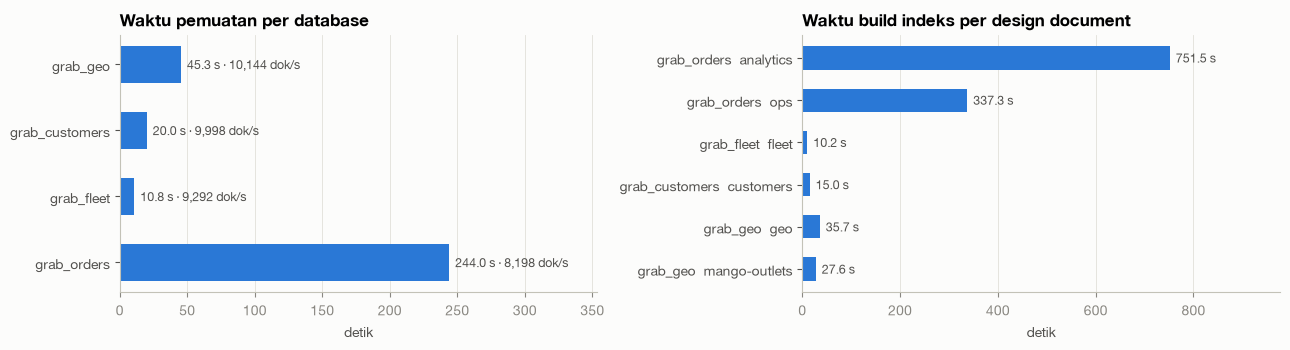

,database,dokumen,gagal,detik,dokumen_per_detik
0,grab_geo,460023,0,45.349,10144.1
1,grab_customers,200000,0,20.005,9997.6
2,grab_fleet,100000,0,10.762,9292.0
3,grab_orders,2000000,0,243.953,8198.3


,database,design_doc,kind,views,build_seconds
0,grab_orders,_design/analytics,javascript views,"[driver_completed_duration, driver_decisions, ...",751.512
1,grab_orders,_design/ops,javascript views,"[by_customer, by_trip, food_by_outlet]",337.321
2,grab_fleet,_design/fleet,javascript views,"[available_vehicles, driver_names, entity_coun...",10.189
3,grab_customers,_design/customers,javascript views,[entity_counts],15.030
4,grab_geo,_design/geo,javascript views,"[areas_by_city_name, entity_counts, locations_...",35.723
5,grab_geo,_design/mango-outlets,mango json index,[open-outlets-by-area],27.556


Total pemuatan: 320.1 s · total build indeks: 1,177.5 s · CouchDB 3.5.3, batch 2000, 4 worker


In [43]:
if load_info:
    loads = pd.DataFrame([{'database': db, 'dokumen': v['documents_written'],
                           'gagal': v['documents_failed'], 'detik': v['load_seconds'],
                           'dokumen_per_detik': v['docs_per_second']}
                          for db, v in load_info['databases'].items()])
    builds = pd.DataFrame(load_info.get('index_builds', []))
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
    ax = axes[0]
    ax.barh(loads['database'], loads['detik'], color=SERIES[0], height=0.55)
    for y, (seconds, rate) in enumerate(zip(loads['detik'], loads['dokumen_per_detik'])):
        ax.text(seconds, y, f'  {seconds:,.1f} s · {rate:,.0f} dok/s', va='center', color=INK2, fontsize=9)
    ax.invert_yaxis(); gridlines(ax); ax.margins(x=0.45)
    ax.set_xlabel('detik'); ax.set_title('Waktu pemuatan per database')
    ax = axes[1]
    if not builds.empty:
        labels = builds['database'] + '  ' + builds['design_doc'].str.replace('_design/', '', regex=False)
        ax.barh(labels, builds['build_seconds'], color=SERIES[0], height=0.55)
        for y, seconds in enumerate(builds['build_seconds']):
            ax.text(seconds, y, f'  {seconds:,.1f} s', va='center', color=INK2, fontsize=9)
        ax.invert_yaxis(); gridlines(ax); ax.margins(x=0.3)
    ax.set_xlabel('detik'); ax.set_title('Waktu build indeks per design document')
    finish(fig, '01_pemuatan_dan_indeks')
    display(loads)
    display(builds)
    print(f"Total pemuatan: {load_info['load_seconds_total']:,.1f} s · total build indeks: "
          f"{load_info.get('index_build_seconds_total') or 0:,.1f} s · CouchDB "
          f"{load_info['couchdb_version']}, batch {load_info['batch_size']}, {load_info['workers']} worker")
else:
    print('Belum ada load_report.json untuk dataset ini (jalankan dengan RUN_LOAD = True).')

### 8.2 Kesetaraan data dengan model relasional (Bab 3.1)

Lingkaran abu-abu adalah jumlah baris di CSV (data relasional Part 2), titik biru adalah jumlah
baris yang tersimpan di CouchDB. Titik tepat di tengah lingkaran berarti jumlahnya sama.

/var/folders/cp/rxyvzx8n00qfs1bbr2t8s8pc0000gp/T/ipykernel_63910/4128884918.py:31: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Helvetica Neue.
  fig.tight_layout()
/var/folders/cp/rxyvzx8n00qfs1bbr2t8s8pc0000gp/T/ipykernel_63910/4128884918.py:32: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Helvetica Neue.
  fig.savefig(FIG_DIR / f'{name}.png', dpi=200, bbox_inches='tight')


/Users/m.nabil/Documents/CODE/IF5101-grab-db-NoSQL/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Helvetica Neue.
  fig.canvas.print_figure(bytes_io, **kw)


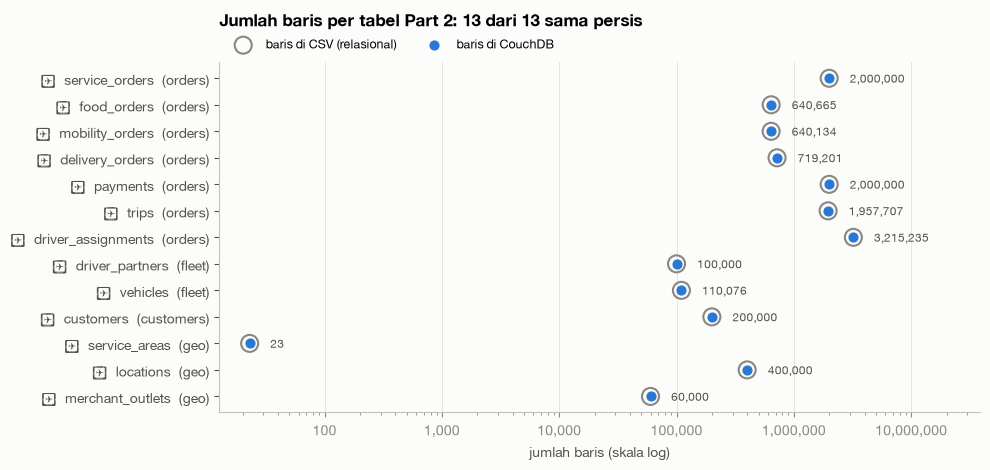

,table,database,csv_rows,couchdb_rows,match
0,service_orders,grab_orders,2000000,2000000,True
1,food_orders,grab_orders,640665,640665,True
2,mobility_orders,grab_orders,640134,640134,True
3,delivery_orders,grab_orders,719201,719201,True
4,payments,grab_orders,2000000,2000000,True
5,trips,grab_orders,1957707,1957707,True
6,driver_assignments,grab_orders,3215235,3215235,True
7,driver_partners,grab_fleet,100000,100000,True
8,vehicles,grab_fleet,110076,110076,True
9,customers,grab_customers,200000,200000,True


**Sampel acak dokumen yang dibandingkan field demi field dengan baris CSV:**

,entitas,dokumen_disampel,tidak_cocok
0,orders,1000,0
1,customers,1000,0
2,driver_partners+vehicles,1000,0
3,service_areas,23,0
4,locations,1000,0
5,merchant_outlets,1000,0


documents per database: {'grab_orders': 2000000, 'grab_fleet': 100000, 'grab_customers': 200000, 'grab_geo': 460023}


In [44]:
if verify_info:
    tables = pd.DataFrame(verify_info['tables'])
    y = list(range(len(tables)))
    fig, ax = plt.subplots(figsize=(10, 4.8))
    ax.scatter(tables['csv_rows'], y, s=150, facecolor='none', edgecolor=MUTED, linewidth=1.5,
               label='baris di CSV (relasional)', zorder=2)
    ax.scatter(tables['couchdb_rows'], y, s=40, color=SERIES[0], label='baris di CouchDB', zorder=3)
    ax.set_yticks(y, [f"{'✓' if m else '✗'}  {t}  ({d.replace('grab_', '')})"
                      for t, m, d in zip(tables['table'], tables['match'], tables['database'])])
    for yy, rows_ in zip(y, tables['csv_rows']):
        ax.text(rows_ * 1.5, yy, f'{rows_:,}', va='center', color=INK2, fontsize=8.5)
    ax.set_xscale('log'); ax.set_xlim(right=tables['csv_rows'].max() * 12)
    plain_log(ax); ax.invert_yaxis(); gridlines(ax)
    ax.set_xlabel('jumlah baris (skala log)')
    ax.set_title(f"Jumlah baris per tabel Part 2: {int(tables['match'].sum())} dari {len(tables)} sama persis",
                 pad=26)
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, fontsize=9)
    finish(fig, '02_kesetaraan_jumlah_baris')
    display(tables)
    samples = pd.DataFrame([{'entitas': k, 'dokumen_disampel': v['sampled'],
                             'tidak_cocok': len(v['mismatches'])}
                            for k, v in verify_info['samples'].items()])
    display(Markdown('**Sampel acak dokumen yang dibandingkan field demi field dengan baris CSV:**'))
    display(samples)
    print('documents per database:', verify_info['documents_per_database'])
else:
    print('Belum ada verify_report.json untuk dataset ini.')

### 8.3 Penyimpanan

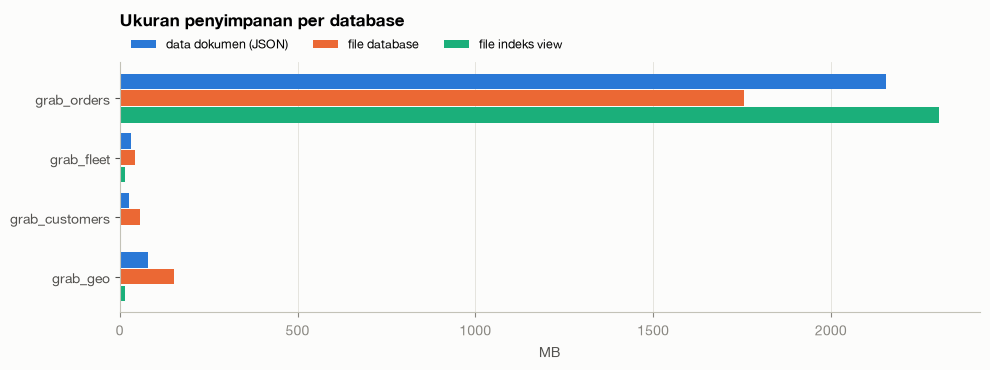

,database,dokumen,data_dokumen_MB,file_database_MB,indeks_view_MB
0,grab_orders,2000003,2155.1,1756.9,2304.0
1,grab_fleet,100002,30.4,42.3,14.5
2,grab_customers,200002,27.0,57.7,2.9
3,grab_geo,460026,79.2,153.5,14.3
total,total,2760033,2291.7,2010.3,2335.7


In [45]:
if load_info and load_info.get('database_sizes'):
    views = load_info.get('view_index_sizes') or {}
    storage = pd.DataFrame([{
        'database': db, 'dokumen': v['doc_count'],
        'data_dokumen_MB': ((v['sizes'] or {}).get('external') or 0) / 2**20,
        'file_database_MB': ((v['sizes'] or {}).get('file') or 0) / 2**20,
        'indeks_view_MB': sum(((s or {}).get('file') or 0) for k, s in views.items()
                              if k.startswith(db + '/')) / 2**20,
    } for db, v in load_info['database_sizes'].items()])
    measures = [('data_dokumen_MB', 'data dokumen (JSON)'), ('file_database_MB', 'file database'),
                ('indeks_view_MB', 'file indeks view')]
if load_info and load_info.get('database_sizes') and storage[[m for m, _ in measures]].to_numpy().sum() > 0:
    fig, ax = plt.subplots(figsize=(10, 3.8))
    height = 0.26
    for i, ((column, label), color) in enumerate(zip(measures, SERIES)):
        positions = [k + (i - 1) * (height + 0.02) for k in range(len(storage))]
        ax.barh(positions, storage[column], height=height, color=color, label=label)
    ax.set_yticks(range(len(storage)), storage['database'])
    ax.invert_yaxis(); gridlines(ax)
    ax.set_xlabel('MB'); ax.set_title('Ukuran penyimpanan per database', pad=26)
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=3, fontsize=9)
    finish(fig, '03_penyimpanan')
if load_info and load_info.get('database_sizes'):
    storage.loc['total'] = storage.sum(numeric_only=True)
    storage.loc['total', 'database'] = 'total'
    display(storage.round(1))
else:
    print('Ukuran penyimpanan tidak tersedia di load_report.json.')

### 8.4 Kebenaran hasil dan waktu eksekusi terhadap target (Bab 3.2)

Titik abu-abu kecil adalah setiap run terukur, titik besar adalah rata-ratanya, garis tegak adalah
target. ✓ berarti run paling lambat masih di bawah target; ✗ berarti melewati target.

/var/folders/cp/rxyvzx8n00qfs1bbr2t8s8pc0000gp/T/ipykernel_63910/4128884918.py:31: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Helvetica Neue.
  fig.tight_layout()
/var/folders/cp/rxyvzx8n00qfs1bbr2t8s8pc0000gp/T/ipykernel_63910/4128884918.py:31: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Helvetica Neue.
  fig.tight_layout()
/var/folders/cp/rxyvzx8n00qfs1bbr2t8s8pc0000gp/T/ipykernel_63910/4128884918.py:32: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Helvetica Neue.
  fig.savefig(FIG_DIR / f'{name}.png', dpi=200, bbox_inches='tight')
/var/folders/cp/rxyvzx8n00qfs1bbr2t8s8pc0000gp/T/ipykernel_63910/4128884918.py:32: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Helvetica Neue.
  fig.savefig(FIG_DIR / f'{name}.png', dpi=200, bbox_inches='tight')


/Users/m.nabil/Documents/CODE/IF5101-grab-db-NoSQL/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10003 (\N{CHECK MARK}) missing from font(s) Helvetica Neue.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/m.nabil/Documents/CODE/IF5101-grab-db-NoSQL/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10007 (\N{BALLOT X}) missing from font(s) Helvetica Neue.
  fig.canvas.print_figure(bytes_io, **kw)


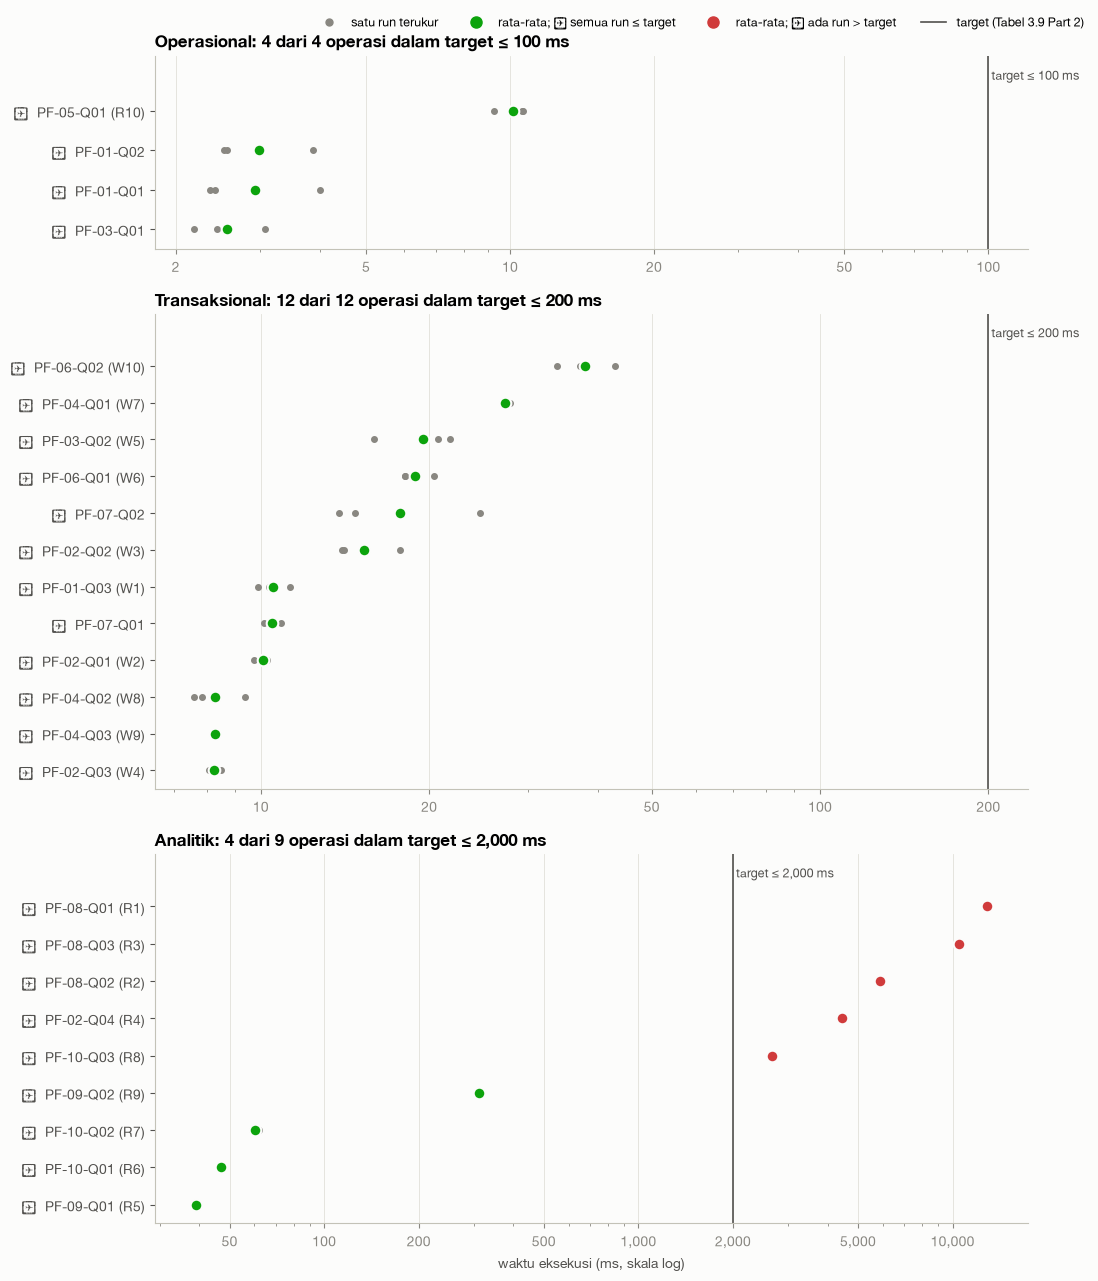

**Hasil benar:** 25 dari 25 operasi benar di setiap run terukur. **Dalam target:** 20 dari 25.

,operation_id,part2,operasi,kategori,rata2_ms,median_ms,terlambat_ms,hasil_benar,target_ms,rasio_thd_target,lulus_target
0,PF-01-Q01,,"Read one order with its subtype, payment, trip...",Operasional,2.923528,2.413000,4.002167,True,100,0.04,True
1,PF-01-Q02,,Read a customer's 20 latest orders,Operasional,2.982083,2.554208,3.872375,True,100,0.04,True
2,PF-01-Q03,W1,Create a confirmed order with its payment and ...,Transaksional,10.499973,10.337667,11.286459,True,200,0.06,True
3,PF-02-Q01,W2,Offer a trip to an available driver,Transaksional,10.071375,10.228667,10.253416,True,200,0.05,True
4,PF-02-Q02,W3,Driver accepts the offer and starts the trip,Transaksional,15.260986,14.092250,17.738667,True,200,0.09,True
5,PF-02-Q03,W4,Driver rejects the offer,Transaksional,8.249264,8.156958,8.496875,True,200,0.04,True
6,PF-02-Q04,R4,Trips offered more than twice and eventually a...,Analitik,4461.570694,4465.874125,4546.462667,True,2000,2.27,False
7,PF-03-Q01,,Read the status of a trip by trip_id,Operasional,2.565764,2.440208,3.068708,True,100,0.03,True
8,PF-03-Q02,W5,Complete a trip and make the driver available,Transaksional,19.502625,20.765458,21.828875,True,200,0.11,True
9,PF-04-Q01,W7,Non-cash checkout that fails once and succeeds...,Transaksional,27.372847,27.140166,27.868417,True,200,0.14,True


In [46]:
if bench_rows:
    def slowest(runs):
        runs = [x for x in runs if x is not None]
        return max(runs) if runs else None
    timing = pd.DataFrame([{
        'operation_id': r['operation_id'], 'part2': META[r['operation_id']].part2_query or '',
        'operasi': META[r['operation_id']].description,
        'kategori': CATEGORY[META[r['operation_id']].kind],
        'run_ms': r['measurements_ms'], 'rata2_ms': r['mean_ms'], 'median_ms': r['median_ms'],
        'terlambat_ms': slowest(r['measurements_ms']),
        'hasil_benar': r['validation']['passed'],
    } for r in bench_rows])
    for column in ('rata2_ms', 'median_ms', 'terlambat_ms'):
        timing[column] = pd.to_numeric(timing[column], errors='coerce')
    timing['target_ms'] = timing['kategori'].map(TARGET_MS)
    timing['rasio_thd_target'] = (timing['terlambat_ms'] / timing['target_ms']).round(2)
    timing['lulus_target'] = timing['terlambat_ms'] <= timing['target_ms']

    counts = timing['kategori'].value_counts()
    fig, axes = plt.subplots(3, 1, figsize=(11, 2.2 + 0.42 * len(timing)),
                             gridspec_kw={'height_ratios': [counts.get(c, 1) + 1.5 for c in TARGET_MS]})
    for ax, (category, target) in zip(axes, TARGET_MS.items()):
        part = timing[timing['kategori'] == category].sort_values('rata2_ms', ascending=False)
        for i, (_, row) in enumerate(part.iterrows()):
            runs = [x for x in row['run_ms'] if x is not None]
            ax.scatter(runs, [i] * len(runs), s=16, color=MUTED, zorder=2)
            if pd.notna(row['rata2_ms']):
                ax.scatter([row['rata2_ms']], [i], s=70, zorder=3, edgecolor=SURFACE, linewidth=1.5,
                           color=GOOD if row['lulus_target'] else CRITICAL)
        ax.axvline(target, color=INK2, linewidth=1.2, zorder=1)
        ax.text(target, -0.9, f' target ≤ {target:,} ms', color=INK2, fontsize=9, va='center')
        ax.set_yticks(range(len(part)), [
            f"{'✓' if ok and good else '✗'}  {oid}" + (f' ({p})' if p else '')
            for oid, p, ok, good in zip(part['operation_id'], part['part2'],
                                        part['lulus_target'], part['hasil_benar'])])
        ax.set_ylim(len(part) - 0.5, -1.4)
        ax.set_xscale('log'); plain_log(ax); gridlines(ax)
        passed = int(part['lulus_target'].sum())
        ax.set_title(f'{category}: {passed} dari {len(part)} operasi dalam target ≤ {target:,} ms')
    axes[-1].set_xlabel('waktu eksekusi (ms, skala log)')
    fig.legend(handles=[
        Line2D([], [], marker='o', linestyle='', color=MUTED, markersize=5, label='satu run terukur'),
        Line2D([], [], marker='o', linestyle='', color=GOOD, markersize=8,
               label='rata-rata; ✓ semua run ≤ target'),
        Line2D([], [], marker='o', linestyle='', color=CRITICAL, markersize=8,
               label='rata-rata; ✗ ada run > target'),
        Line2D([], [], color=INK2, linewidth=1.2, label='target (Tabel 3.9 Part 2)'),
    ], loc='upper right', ncol=4, fontsize=9, bbox_to_anchor=(1, 1.01))
    finish(fig, '04_waktu_eksekusi_vs_target')
    shown = timing.drop(columns=['run_ms']).sort_values('operation_id').reset_index(drop=True)
    shown.to_csv(OUT_DIR / 'analysis_timing.csv', index=False)
    display(Markdown(
        f"**Hasil benar:** {int(timing['hasil_benar'].sum())} dari {len(timing)} operasi benar di "
        f"setiap run terukur. **Dalam target:** {int(timing['lulus_target'].sum())} dari {len(timing)}."))
    display(shown)
else:
    print('Belum ada hasil benchmark untuk dataset ini (jalankan dengan RUN_BENCHMARK = True).')

### 8.5 Faktor yang memengaruhi waktu eksekusi

Dua faktor yang diukur langsung dari eksekusi tunggal di bagian 4: **jumlah baris/dokumen yang
dikirim CouchDB ke client** (untuk kueri top-N dan agregasi, CouchDB mengirim semua grup view
lalu client memilih atau menggabungkannya, jadi angka ini bisa jauh lebih besar dari hasil
akhir), dan **jumlah request HTTP** per operasi (CouchDB tidak punya join atau transaksi
multi-dokumen, jadi keduanya dikerjakan dengan beberapa request).

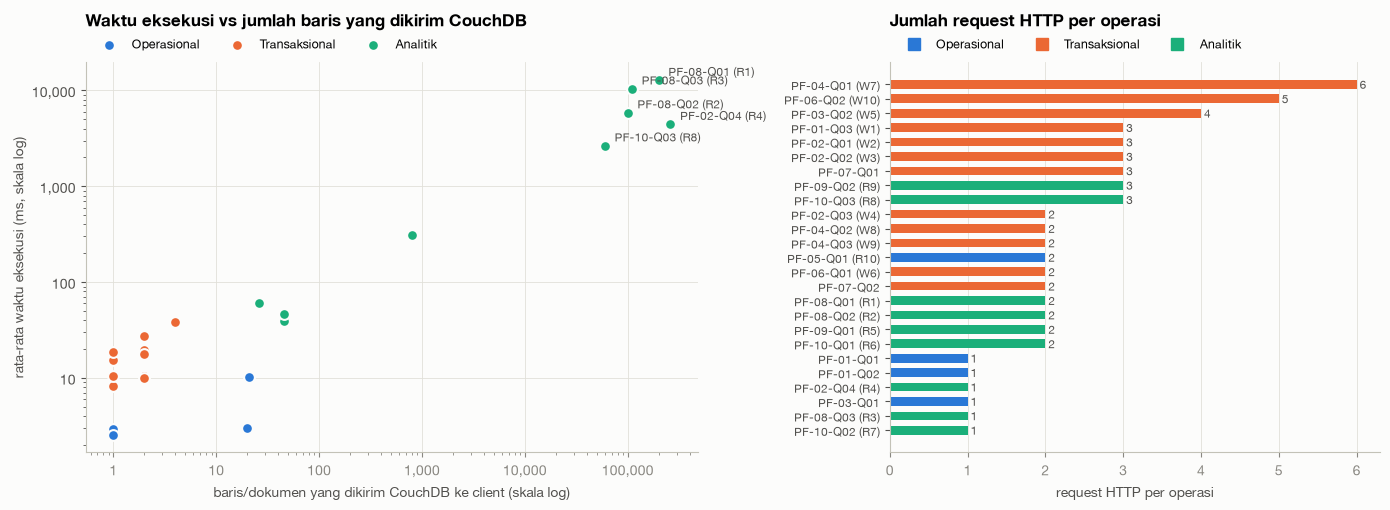

,operation_id,part2,kategori,rows,couch_rows,requests,rata2_ms,target_ms,lulus_target
0,PF-08-Q01,R1,Analitik,99752.0,200000,2,12842.064361,2000,False
1,PF-08-Q03,R3,Analitik,144.0,110065,1,10458.348653,2000,False
2,PF-08-Q02,R2,Analitik,10.0,100001,2,5891.931875,2000,False
3,PF-02-Q04,R4,Analitik,260024.0,260024,1,4461.570694,2000,False
4,PF-10-Q03,R8,Analitik,10.0,60009,3,2661.271056,2000,False
5,PF-09-Q02,R9,Analitik,23.0,799,3,310.801014,2000,True
6,PF-10-Q02,R7,Analitik,26.0,26,1,60.109333,2000,True
7,PF-10-Q01,R6,Analitik,23.0,46,2,47.040000,2000,True
8,PF-09-Q01,R5,Analitik,23.0,46,2,39.103375,2000,True
9,PF-06-Q02,W10,Transaksional,NaN,4,5,38.006778,200,True


In [47]:
if bench_rows and not once.empty and timing['rata2_ms'].notna().any():
    has_requests = 'requests' in once.columns
    has_couch_rows = 'couch_rows' in once.columns
    factors = timing.merge(once[['operation_id', 'rows'] + (['requests'] if has_requests else [])
                                + (['couch_rows'] if has_couch_rows else [])],
                           on='operation_id', how='left')
    measure = 'couch_rows' if has_couch_rows else 'rows'
    factors['baris_hasil'] = factors[measure].fillna(1).clip(lower=1)
    if has_requests:
        fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1.25, 1]})
    else:  # evidence from a run that did not count HTTP requests yet
        fig, axis = plt.subplots(figsize=(9, 5.2))
        axes = [axis]
    ax = axes[0]
    for category, color in CATEGORY_COLOR.items():
        part = factors[factors['kategori'] == category]
        ax.scatter(part['baris_hasil'], part['rata2_ms'], s=60, color=color, edgecolor=SURFACE,
                   linewidth=1.5, label=category, zorder=3)
    for _, row in factors.nlargest(5, 'rata2_ms').iterrows():
        ax.annotate(row['operation_id'] + (f" ({row['part2']})" if row['part2'] else ''),
                    (row['baris_hasil'], row['rata2_ms']), textcoords='offset points',
                    xytext=(7, 3), fontsize=8.5, color=INK2)
    ax.set_xscale('log'); ax.set_yscale('log'); plain_log(ax, 'both'); gridlines(ax, 'both')
    ax.set_xlabel(('baris/dokumen yang dikirim CouchDB ke client' if has_couch_rows
                   else 'baris hasil akhir (operasi tulis dihitung 1)') + ' (skala log)')
    ax.set_ylabel('rata-rata waktu eksekusi (ms, skala log)')
    ax.set_title('Waktu eksekusi vs jumlah baris' + (' yang dikirim CouchDB' if has_couch_rows
                                                       else ' hasil'), pad=26)
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=3, fontsize=9)
    if has_requests:
        ax = axes[1]
        order = factors.sort_values(['requests', 'operation_id'], ascending=[False, True])
        ax.barh(order['operation_id'] + order['part2'].map(lambda p: f' ({p})' if p else ''),
                order['requests'], color=[CATEGORY_COLOR[c] for c in order['kategori']], height=0.6)
        for y, n in enumerate(order['requests']):
            ax.text(n, y, f' {int(n)}', va='center', color=INK2, fontsize=8.5)
        ax.invert_yaxis(); gridlines(ax); ax.tick_params(axis='y', labelsize=8.5)
        ax.set_xlabel('request HTTP per operasi'); ax.set_title('Jumlah request HTTP per operasi', pad=26)
        ax.legend(handles=[Line2D([], [], marker='s', linestyle='', color=c, markersize=8, label=k)
                           for k, c in CATEGORY_COLOR.items()], loc='lower left', bbox_to_anchor=(0, 1.0),
                  ncol=3, fontsize=9)
    finish(fig, '05_faktor_baris_dan_request')
    columns = ['operation_id', 'part2', 'kategori', 'rows'] + (['couch_rows'] if has_couch_rows else []) \
        + (['requests'] if has_requests else []) + ['rata2_ms', 'target_ms', 'lulus_target']
    display(factors[columns].sort_values('rata2_ms', ascending=False).reset_index(drop=True))
    if not has_requests:
        print('Jumlah request HTTP tidak tercatat di operations_once.csv run ini (fitur ditambahkan kemudian).')

### 8.6 Pengaruh volume data: sampel 40 ribu vs data penuh 2 juta order

Muncul bila kedua dataset sudah dijalankan dengan `RUN_BENCHMARK = True` (folder
`couchdb_sample` dan `couchdb_canonical`).

In [48]:
runs_by_dataset = {}
for folder in sorted((ROOT / 'benchmarks' / 'results').glob('couchdb_*')):
    if (folder / 'results.json').is_file():
        doc = json.loads((folder / 'results.json').read_text())
        runs_by_dataset[folder.name.removeprefix('couchdb_')] = {
            r['operation_id']: r['mean_ms'] for r in doc['results'] if r.get('dbms') == 'couchdb'}
small, full = runs_by_dataset.get('sample', {}), runs_by_dataset.get('canonical', {})
scale = pd.DataFrame([{'operation_id': k, 'part2': META[k].part2_query or '',
                       'sampel_40rb_ms': small[k], 'penuh_2jt_ms': full[k]}
                      for k in small if small.get(k) and full.get(k)])
if len(scale):
    scale['kenaikan_kali'] = (scale['penuh_2jt_ms'] / scale['sampel_40rb_ms']).round(1)
    scale = scale.sort_values('penuh_2jt_ms', ascending=False).reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(10, 0.6 + 0.34 * len(scale)))
    for y, row in scale.iterrows():
        ax.plot([row['sampel_40rb_ms'], row['penuh_2jt_ms']], [y, y], color=GRID, linewidth=2, zorder=1)
    ax.scatter(scale['sampel_40rb_ms'], scale.index, s=46, color=LIGHT_BLUE, zorder=2,
               label='sampel 40 ribu order')
    ax.scatter(scale['penuh_2jt_ms'], scale.index, s=46, color=DARK_BLUE, zorder=3,
               label='data penuh 2 juta order')
    ax.set_yticks(scale.index, scale['operation_id'] + scale['part2'].map(lambda p: f' ({p})' if p else ''))
    ax.invert_yaxis(); ax.set_xscale('log'); plain_log(ax); gridlines(ax)
    ax.tick_params(axis='y', labelsize=8.5)
    ax.set_xlabel('rata-rata waktu eksekusi (ms, skala log)')
    ax.set_title('Waktu eksekusi pada dua ukuran data', pad=26)
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1.0), ncol=2, fontsize=9)
    finish(fig, '06_pengaruh_volume_data')
    display(scale)
else:
    print('Perbandingan volume butuh hasil benchmark yang berhasil untuk kedua dataset '
          '(couchdb_sample dan couchdb_canonical); tersedia:', sorted(runs_by_dataset))

Perbandingan volume butuh hasil benchmark yang berhasil untuk kedua dataset (couchdb_sample dan couchdb_canonical); tersedia: ['canonical']


### 8.7 Pemenuhan kebutuhan Bab 1 dan ringkasan temuan

In [49]:
tests_text = (OUT_DIR / 'tests.txt').read_text() if (OUT_DIR / 'tests.txt').is_file() else ''
passed_tests = re.search(r'(\d+) passed', tests_text)
failed_tests = re.search(r'(\d+) failed', tests_text)
if bench_rows:
    requirement_rows = []
    for requirement in sorted({r for op in OPERATIONS for r in op.requirement_ids if r.startswith('PF')}):
        ops = [op.operation_id for op in OPERATIONS if requirement in op.requirement_ids]
        part = timing[timing['operation_id'].isin(ops)]
        requirement_rows.append({
            'kebutuhan': requirement, 'operasi': ', '.join(ops),
            'semua_hasil_benar': '✓' if part['hasil_benar'].all() else '✗',
            'semua_dalam_target': '✓' if part['lulus_target'].all() else '✗ ' + ', '.join(
                part.loc[~part['lulus_target'], 'operation_id'])})
    display(pd.DataFrame(requirement_rows))
    rows_total = sum(t['csv_rows'] for t in verify_info['tables']) if verify_info else None
    docs_total = sum(verify_info['documents_per_database'].values()) if verify_info else None
    display(pd.DataFrame([
        {'kebutuhan': 'PNF-03 Kinerja akses data',
         'bukti': f"{int(timing['lulus_target'].sum())}/{len(timing)} operasi dalam target Tabel 3.9 Part 2"},
        {'kebutuhan': 'PNF-04 Konsistensi dan integritas',
         'bukti': f"tes aturan integritas: {passed_tests.group(1) if passed_tests else 0} lulus, "
                  f"{failed_tests.group(1) if failed_tests else 0} gagal (lihat tests.txt)"},
        {'kebutuhan': 'PNF-06 Fleksibilitas struktur data',
         'bukti': 'subtipe food/mobility/delivery tersimpan sebagai objek tertanam dengan atribut berbeda'},
        {'kebutuhan': 'PNF-07 Efisiensi sumber daya',
         'bukti': (f'{rows_total:,} baris relasional tersimpan dalam {docs_total:,} dokumen'
                   if rows_total else 'lihat 8.3')},
        {'kebutuhan': 'PNF-01, PNF-02, PNF-05',
         'bukti': 'tidak diuji: CouchDB berjalan sebagai satu node, tanpa replikasi atau cluster'},
    ]))
    ranked = timing.dropna(subset=['rata2_ms']).sort_values('rata2_ms')
    fastest = ', '.join(f"{r.operation_id} {r.rata2_ms:,.1f} ms" for r in ranked.head(3).itertuples())
    slowest_ = ', '.join(f"{r.operation_id} {r.rata2_ms:,.1f} ms" for r in ranked.tail(3)[::-1].itertuples())
    over = timing[~timing['lulus_target']].sort_values('rasio_thd_target', ascending=False)
    lines = [
        f"- Dataset `{DATASET}`: {environment['dataset_orders']:,} order, CouchDB {environment['couchdb_version']}, "
        f"commit `{environment['git_commit'][:7]}`.",
        f"- Hasil benar: {int(timing['hasil_benar'].sum())}/{len(timing)} operasi; dalam target: "
        f"{int(timing['lulus_target'].sum())}/{len(timing)}.",
        f"- Tercepat: {fastest}.",
        f"- Terlambat: {slowest_}.",
    ]
    if len(over):
        lines.append('- Melewati target: ' + ', '.join(
            f"{r.operation_id}{' (' + r.part2 + ')' if r.part2 else ''} {r.rasio_thd_target}× target"
            for r in over.itertuples()) + '.')
    if load_info:
        lines.append(f"- Pemuatan {load_info['load_seconds_total']:,.0f} s, build indeks "
                     f"{load_info.get('index_build_seconds_total') or 0:,.0f} s.")
    summary_md = '\n'.join(lines)
    (OUT_DIR / 'analysis_summary.md').write_text(summary_md + '\n')
    display(Markdown('**Ringkasan temuan (otomatis dari bukti):**\n\n' + summary_md))

,kebutuhan,operasi,semua_hasil_benar,semua_dalam_target
0,PF-01,"PF-01-Q01, PF-01-Q02, PF-01-Q03",✓,✓
1,PF-02,"PF-02-Q01, PF-02-Q02, PF-02-Q03, PF-02-Q04",✓,✗ PF-02-Q04
2,PF-03,"PF-02-Q02, PF-03-Q01, PF-03-Q02",✓,✓
3,PF-04,"PF-04-Q01, PF-04-Q02, PF-04-Q03",✓,✓
4,PF-05,PF-05-Q01,✓,✓
5,PF-06,"PF-06-Q01, PF-06-Q02",✓,✓
6,PF-07,"PF-07-Q01, PF-07-Q02",✓,✓
7,PF-08,"PF-02-Q04, PF-08-Q01, PF-08-Q02, PF-08-Q03",✓,"✗ PF-02-Q04, PF-08-Q01, PF-08-Q02, PF-08-Q03"
8,PF-09,"PF-09-Q01, PF-09-Q02",✓,✓
9,PF-10,"PF-10-Q01, PF-10-Q02, PF-10-Q03",✓,✗ PF-10-Q03


,kebutuhan,bukti
0,PNF-03 Kinerja akses data,20/25 operasi dalam target Tabel 3.9 Part 2
1,PNF-04 Konsistensi dan integritas,"tes aturan integritas: 26 lulus, 0 gagal (liha..."
2,PNF-06 Fleksibilitas struktur data,subtipe food/mobility/delivery tersimpan sebag...
3,PNF-07 Efisiensi sumber daya,"12,043,041 baris relasional tersimpan dalam 2,..."
4,"PNF-01, PNF-02, PNF-05",tidak diuji: CouchDB berjalan sebagai satu nod...


**Ringkasan temuan (otomatis dari bukti):**

- Dataset `canonical`: 2,000,000 order, CouchDB 3.5.3, commit `954367b`.
- Hasil benar: 25/25 operasi; dalam target: 20/25.
- Tercepat: PF-03-Q01 2.6 ms, PF-01-Q01 2.9 ms, PF-01-Q02 3.0 ms.
- Terlambat: PF-08-Q01 12,842.1 ms, PF-08-Q03 10,458.3 ms, PF-08-Q02 5,891.9 ms.
- Melewati target: PF-08-Q01 (R1) 6.5× target, PF-08-Q03 (R3) 5.28× target, PF-08-Q02 (R2) 2.98× target, PF-02-Q04 (R4) 2.27× target, PF-10-Q03 (R8) 1.34× target.
- Pemuatan 320 s, build indeks 1,178 s.

## 9. Audit manifest

The SHA-256 of every evidence file (including the figures) is written to `MANIFEST.json`;
with `PUBLISH = True` the evidence is copied to `benchmarks/published/` so it can be committed.

In [50]:
environment['run_finished_utc'] = datetime.now(UTC).isoformat()
(OUT_DIR / 'environment.json').write_text(json.dumps(environment, indent=2) + '\n')
files = {f.name: {'bytes': f.stat().st_size, 'sha256': sha256(f)}
         for f in sorted(OUT_DIR.iterdir()) if f.is_file() and f.name != 'MANIFEST.json'}
files[REFERENCE_FILE.name] = {'bytes': REFERENCE_FILE.stat().st_size, 'sha256': sha256(REFERENCE_FILE),
                              'note': 'expected results, kept in data/reference (not published)'}
(OUT_DIR / 'MANIFEST.json').write_text(json.dumps(files, indent=2) + '\n')
if PUBLISH:
    target = ROOT / 'benchmarks' / 'published' / OUT_DIR.name
    shutil.copytree(OUT_DIR, target, dirs_exist_ok=True)
    print(f'Evidence copied to {target.relative_to(ROOT)} (commit it to keep it)')
pd.DataFrame(files).T

,bytes,sha256,note
analysis_summary.md,479,39241d20c70cdcbb977944d4d03603248a8e7bf4b51c2d...,NaN
analysis_timing.csv,3113,d4d813bad1d227548d27012115ac391f91179867b2870c...,NaN
benchmark_summary.csv,2103,fdfec707ae99f8a3d39bb597984bc77c0660aa05502053...,NaN
environment.json,2231,5dd4f21ce16326cdc9613203314e8461c6bd62dc56c22d...,NaN
load_report.json,4236,c0dba4beac60be06f024d00cb4ebf71a67e115ff812bcf...,NaN
operations_once.csv,2641,066dc8f4503994a5ef8e25b9bda120ee5714ffed4598f0...,NaN
results.json,73987,732c3026940016d760b599083d0e90c9dd23fa19bc6027...,NaN
runs.csv,4692,3ebe1318fc8390462fd4796f7b235e9cc7bf8f1f86956b...,NaN
tests.txt,3208,5a6d29cac28477a56567b405fa8b2ef49dda01d2f5c027...,NaN
verify_report.json,2707,a798c55f454e9681115cdbb7144d9747f948958a6dfa0f...,NaN
